# Proyecto 2: Contando clientes con modelos *Buy 'Til You Die*

**Análisis y Ciencia de Datos — Universidad del Istmo de Guatemala**

Este notebook corre de principio a fin a partir de los archivos originales
(`data/CDNOW_sample.txt` y `data/Online Retail.xlsx`). El BG/NBD, el
MBG/NBD y todas sus cantidades derivadas están programados a mano en el
paquete `btyd/` usando solo `scipy.special.gammaln`, `betaln`, `hyp2f1` y
`scipy.optimize.minimize`.

In [1]:
import inspect
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize
from scipy.special import gammaln
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (brier_score_loss, confusion_matrix,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from btyd import bgnbd, data, mbgnbd

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)
RES = Path("resultados")
RES.mkdir(exist_ok=True)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIG / f"{nombre}.png", dpi=160, bbox_inches="tight")
    plt.show()


def tabla(df, nombre):
    df.to_csv(RES / f"{nombre}.csv")
    return df

## 0. Los datos: preparación

**0.1** Si un cliente compró dos veces el mismo día, se cuenta como una sola
transacción (se suman CDs y montos). **0.2** El tiempo se mide en semanas
(días/7) con el día 0 = 1 de enero de 1997. Calibración: 1-ene a 30-sep-1997
(39 semanas); *holdout*: 1-oct-1997 a 30-jun-1998 (39 semanas).

In [2]:
trans = data.leer_cdnow()
crudo = pd.read_csv(data.DATA / "CDNOW_sample.txt", sep=r"\s+", header=None)
print(f"Registros en el archivo original: {len(crudo):,}")
print(f"Transacciones (cliente-día):       {len(trans):,}")
print(f"Clientes:                          {trans['id'].nunique():,}")
print("Rango de fechas:", trans["fecha"].min().date(), "a", trans["fecha"].max().date())

Registros en el archivo original: 6,919
Transacciones (cliente-día):       6,696
Clientes:                          2,357
Rango de fechas: 1997-01-01 a 1998-06-30


**0.3** Para cada cliente: $x$ = compras repetidas en calibración, $t_x$ =
momento de la última compra medido desde la primera, $T$ = (30-sep − primera
compra)/7 y $x^*$ = compras en el *holdout*.

In [3]:
d = data.cdnow_rfm()
x, tx, T, xs = (d[c].to_numpy(float) for c in ["x", "tx", "T", "x_star"])
print(d.head())
print(d[["x", "tx", "T", "x_star"]].describe().round(3))
print(f"\nCompras repetidas en calibración: {x.sum():.0f};  en holdout: {xs.sum():.0f}")

      primera  x       tx        T   t0  x_star
id                                             
1  1997-01-01  2  30.4286  38.8571  0.0       1
2  1997-01-01  1   1.7143  38.8571  0.0       0
3  1997-01-01  0   0.0000  38.8571  0.0       0
4  1997-01-01  0   0.0000  38.8571  0.0       0
5  1997-01-01  0   0.0000  38.8571  0.0       0
              x        tx         T    x_star
count  2357.000  2357.000  2357.000  2357.000
mean      1.042     6.846    32.716     0.798
std       2.190    10.731     3.327     2.057
min       0.000     0.000    27.000     0.000
25%       0.000     0.000    29.857     0.000
50%       0.000     0.000    32.714     0.000
75%       1.000    12.000    35.429     1.000
max      29.000    38.429    38.857    34.000

Compras repetidas en calibración: 2457;  en holdout: 1882


0.4  Fracción sin compras repetidas en calibración: 0.599 (1411 de 2357)
     T va de 27.00 a 38.86 semanas


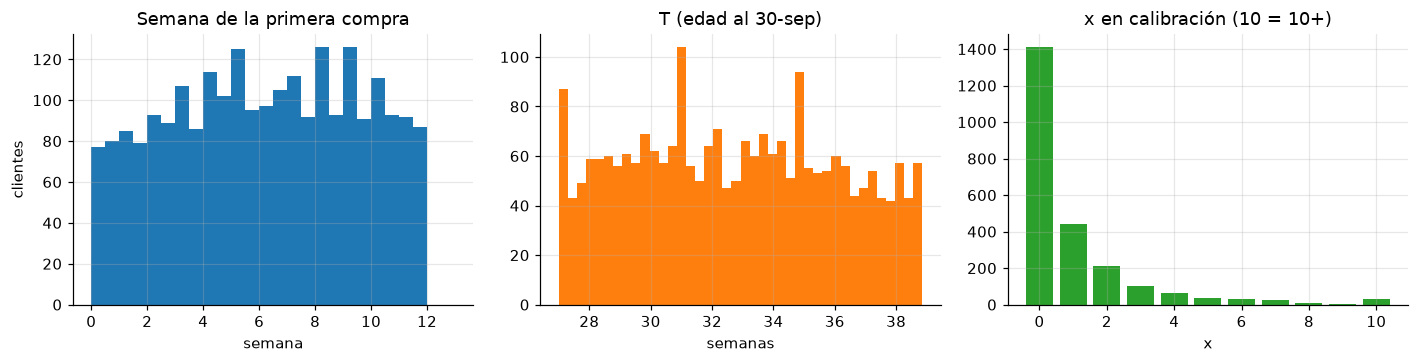

In [4]:
frac0 = (x == 0).mean()
print(f"0.4  Fracción sin compras repetidas en calibración: {frac0:.3f} "
      f"({(x == 0).sum()} de {len(x)})")
print(f"     T va de {T.min():.2f} a {T.max():.2f} semanas")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(d["t0"], bins=np.arange(0, 13.5, 0.5), color="C0")
ax[0].set(title="Semana de la primera compra", xlabel="semana", ylabel="clientes")
ax[1].hist(T, bins=40, color="C1")
ax[1].set(title="T (edad al 30-sep)", xlabel="semanas")
cnt = pd.Series(np.minimum(x, 10)).value_counts().sort_index()
ax[2].bar(cnt.index, cnt.values, color="C2")
ax[2].set(title="x en calibración (10 = 10+)", xlabel="x")
guardar(fig, "00_datos")

**0.4 Respuesta.** El 59.9% de los clientes (1,411 de 2,357) no volvió a
comprar durante las 39 semanas de calibración: el "grupo silencioso" es la
mayoría, y cualquier modelo tiene que decir algo sensato sobre ellos.

$T$ es distinto para cada cliente porque la cohorte se **adquirió de forma
escalonada** a lo largo del primer trimestre (primeras compras del 1 de enero
al 25 de marzo), pero la calibración termina en la misma fecha calendario
para todos (30 de septiembre). Un cliente que llegó el 1 de enero tuvo 38.86
semanas para recomprar; uno que llegó el 25 de marzo solo 27. Por eso la
verosimilitud condiciona en $T_i$: no ver compras en una ventana corta dice
menos que no verlas en una larga. (En la gráfica de la izquierda también se
ve el patrón de adquisición: muchos clientes la primera semana de enero.)

---
## Parte 1: el modelo, pieza por pieza

Supuestos del BG/NBD: (i) mientras está activo, el cliente $i$ compra según
un proceso de Poisson con tasa $\lambda_i$; (ii) $\lambda \sim
\text{Gamma}(r,\alpha)$; (iii) después de **cada** compra (repetida) muere
con probabilidad $p_i$; (iv) $p\sim\text{Beta}(a,b)$; (v) $\lambda_i \perp p_i$.

### 1.1 Un cliente

Fijemos $\lambda$ y $p$. Observamos $x$ compras repetidas en $(0,T]$ en los
momentos $t_1<\dots<t_x=t_x$, y ninguna en $(t_x, T]$. Hay **dos historias**
que producen exactamente estos datos:

**Historia A — sigue vivo en $T$.** Los tiempos entre compras son
exponenciales: la densidad de las $x$ compras es
$\lambda e^{-\lambda t_1}\cdot\lambda e^{-\lambda(t_2-t_1)}\cdots\lambda e^{-\lambda(t_x-t_{x-1})}
= \lambda^x e^{-\lambda t_x}$. Sobrevivió a cada una de las $x$ compras:
$(1-p)^x$. Y, estando vivo, no compró en $(t_x,T]$: $e^{-\lambda(T-t_x)}$.
Multiplicando,
$$L_A=(1-p)^x\,\lambda^x e^{-\lambda T}.$$

**Historia B — murió justo después de la $x$-ésima compra.** La densidad de
las compras es la misma, $\lambda^x e^{-\lambda t_x}$; sobrevivió a las
primeras $x-1$, $(1-p)^{x-1}$, y murió después de la última, $p$. Ya muerto,
no comprar en $(t_x, T]$ tiene probabilidad 1:
$$L_B = p(1-p)^{x-1}\lambda^x e^{-\lambda t_x}.$$

Las historias son excluyentes, así que la verosimilitud es la suma:
$$L(\lambda,p\mid x,t_x,T) = (1-p)^x\lambda^x e^{-\lambda T} + \delta_{x>0}\,p(1-p)^{x-1}\lambda^x e^{-\lambda t_x}.$$

**¿Por qué la historia B no existe si $x=0$?** En el BG/NBD la muerte solo
puede ocurrir *justo después de una compra repetida*. Si $x=0$ no hubo
ninguna compra en $(0,T]$ después de la cual morir; la primera compra (en
$t=0$) no cuenta como oportunidad de muerte. Un cliente con $x=0$ está, por
construcción, vivo en $T$. (Esta es la pieza que va a importar en la Parte 4.)

Nótese que solo aparecen $x$, $t_x$ y $T$: los momentos de las compras
intermedias se cancelan, por eso $(x,t_x,T)$ son estadísticos suficientes.

### 1.2 La mezcla

Integramos sobre $\lambda\sim\text{Gamma}(r,\alpha)$, con densidad
$g(\lambda)=\alpha^r\lambda^{r-1}e^{-\alpha\lambda}/\Gamma(r)$, y sobre
$p\sim\text{Beta}(a,b)$, con densidad $f(p)=p^{a-1}(1-p)^{b-1}/B(a,b)$. Por
(v), cada término se factoriza en una integral en $\lambda$ por una en $p$.

**Integral en $\lambda$** (la misma de la mezcla gamma–Poisson): para $s\in\{T, t_x\}$,
$$\int_0^\infty \lambda^x e^{-\lambda s}\frac{\alpha^r\lambda^{r-1}e^{-\alpha\lambda}}{\Gamma(r)}d\lambda
=\frac{\alpha^r}{\Gamma(r)}\int_0^\infty\lambda^{r+x-1}e^{-(\alpha+s)\lambda}d\lambda
=\frac{\Gamma(r+x)\,\alpha^r}{\Gamma(r)}\,\frac{1}{(\alpha+s)^{r+x}},$$
porque el integrando es el núcleo de una $\text{Gamma}(r+x,\alpha+s)$.

**Integrales en $p$** (definición de la función beta):
$$\int_0^1 (1-p)^x\frac{p^{a-1}(1-p)^{b-1}}{B(a,b)}dp=\frac{B(a,b+x)}{B(a,b)},\qquad
\int_0^1 p(1-p)^{x-1}\frac{p^{a-1}(1-p)^{b-1}}{B(a,b)}dp=\frac{B(a+1,b+x-1)}{B(a,b)}.$$

Juntando:
$$L(r,\alpha,a,b\mid x,t_x,T)=\frac{\Gamma(r+x)\,\alpha^r}{\Gamma(r)}\left[\frac{B(a,b+x)}{B(a,b)}\frac{1}{(\alpha+T)^{r+x}}
+\delta_{x>0}\frac{B(a+1,b+x-1)}{B(a,b)}\frac{1}{(\alpha+t_x)^{r+x}}\right].$$

La log-verosimilitud de la muestra es $\sum_i \log L_i$. Una consecuencia
útil: para $x=0$, $B(a,b+0)/B(a,b)=1$ y $L_i=\left(\frac{\alpha}{\alpha+T_i}\right)^r$
**no depende de $a$ ni de $b$**. Los clientes sin recompras no aportan
ninguna información sobre la muerte.

La implementación (archivo `btyd/bgnbd.py`) trabaja en logaritmos, usa
`np.logaddexp` para sumar las dos historias y evalúa el segundo término solo
para $x>0$ (poniendo $-\infty$ en su logaritmo cuando $x=0$):

In [5]:
print(inspect.getsource(bgnbd.loglik_individual))

def loglik_individual(params, x, tx, T):
    """log L_i(r, alpha, a, b | x_i, tx_i, T_i) para cada cliente (ec. 1.2)."""
    r, alpha, a, b = params
    x = np.asarray(x, dtype=float)
    tx = np.asarray(tx, dtype=float)
    T = np.asarray(T, dtype=float)

    # Gamma(r + x) alpha^r / Gamma(r)
    comun = gammaln(r + x) - gammaln(r) + r * np.log(alpha)
    # Historia 1: sigue vivo hasta T
    t1 = betaln(a, b + x) - betaln(a, b) - (r + x) * np.log(alpha + T)
    # Historia 2: murió justo después de la x-ésima compra (solo si x > 0).
    # Se evalúa solo donde x > 0 para no meter betaln(a+1, b-1) basura.
    pos = x > 0
    t2 = np.full_like(x, -np.inf)
    xp = x[pos]
    t2[pos] = (betaln(a + 1, b + xp - 1) - betaln(a, b)
               - (r + xp) * np.log(alpha + tx[pos]))
    return comun + np.logaddexp(t1, t2)



**Chequeo de la integral.** Antes de simular, verificamos numéricamente que
la fórmula cerrada de 1.2 es la integral de la de 1.1: tomamos millones de
$(\lambda, p)$ de la gamma y la beta y promediamos $L(\lambda,p\mid x,t_x,T)$
(Monte Carlo) para varios clientes.

In [6]:
rng = np.random.default_rng(1)
par_prueba = np.array([0.25, 4.0, 0.8, 2.5])
n_mc = 4_000_000
lam = rng.gamma(par_prueba[0], 1 / par_prueba[1], n_mc)
pp = rng.beta(par_prueba[2], par_prueba[3], n_mc)
filas = []
for (xi, txi, Ti) in [(0, 0, 30), (1, 10, 35), (3, 20, 38), (7, 30, 39), (2, 2, 27)]:
    L1 = (1 - pp) ** xi * lam ** xi * np.exp(-lam * Ti)
    if xi > 0:
        L1 = L1 + pp * (1 - pp) ** (xi - 1) * lam ** xi * np.exp(-lam * txi)
    mc = L1.mean()
    cerrada = np.exp(bgnbd.loglik_individual(par_prueba, [xi], [txi], [Ti]))[0]
    filas.append({"x": xi, "tx": txi, "T": Ti, "Monte Carlo": mc,
                  "fórmula 1.2": cerrada, "error rel.": mc / cerrada - 1})
pd.DataFrame(filas)

,x,tx,T,Monte Carlo,fórmula 1.2,error rel.
0,0,0,30,5.8578e-01,5.8566e-01,2.1126e-04
1,1,10,35,5.9129e-03,5.9132e-03,-4.3747e-05
2,3,20,38,5.7853e-06,5.7851e-06,4.2016e-05
3,7,30,39,3.3013e-10,3.3003e-10,2.8134e-04
4,2,2,27,1.2252e-03,1.2257e-03,-3.9647e-04


### 1.3 Primero, datos que nosotros inventamos

Simulamos 2,357 clientes con $(r,\alpha,a,b) = (0.25, 4, 0.8, 2.5)$ y
$T\sim U(27, 39)$ semanas, y estimamos con nuestra verosimilitud. Repetimos
con **50 semillas**. La simulación sigue la historia del modelo: tiempos
entre compras exponenciales con tasa $\lambda_i$ y, después de cada compra
repetida, el cliente muere con probabilidad $p_i$.

In [7]:
VERDAD = np.array([0.25, 4.0, 0.8, 2.5])
N_SEM = 50
est = []
for s in range(N_SEM):
    rng = np.random.default_rng(1000 + s)
    Ts = rng.uniform(27, 39, 2357)
    xs_, txs_, Ts_, _, _ = bgnbd.simulate(VERDAD, Ts, rng)
    f = bgnbd.fit(xs_, txs_, Ts_, seed=s)
    est.append(np.r_[f["params"], f["loglik"], (xs_ == 0).mean()])
est = pd.DataFrame(est, columns=["r", "alpha", "a", "b", "loglik", "frac_x0"])
est["r/alpha"] = est["r"] / est["alpha"]
est["a/(a+b)"] = est["a"] / (est["a"] + est["b"])
verdad_ext = pd.Series({"r": 0.25, "alpha": 4.0, "a": 0.8, "b": 2.5,
                        "r/alpha": 0.25 / 4, "a/(a+b)": 0.8 / 3.3})
cols = list(verdad_ext.index)
res13 = pd.DataFrame({
    "verdadero": verdad_ext,
    "media": est[cols].mean(),
    "desv. est.": est[cols].std(),
    "sesgo %": 100 * (est[cols].mean() / verdad_ext - 1),
    "CV % (desv/verdad)": 100 * est[cols].std() / verdad_ext,
    "IC 95% cubre": [np.mean(np.abs(est[c] - verdad_ext[c]) <= 1.96 * est[c].std()) for c in cols],
})
tabla(res13.round(4), "1_3_simulacion")

,verdadero,media,desv. est.,sesgo %,CV % (desv/verdad),IC 95% cubre
r,0.2500,0.2536,0.0099,1.4496,3.9701,0.92
alpha,4.0000,4.0476,0.2742,1.1907,6.8548,0.94
a,0.8000,0.8594,0.1953,7.4275,24.4108,0.94
b,2.5000,2.7472,0.7272,9.8892,29.0881,0.94
r/alpha,0.0625,0.0628,0.0031,0.5312,4.9907,0.92
a/(a+b),0.2424,0.2405,0.0178,-0.7871,7.3597,0.96


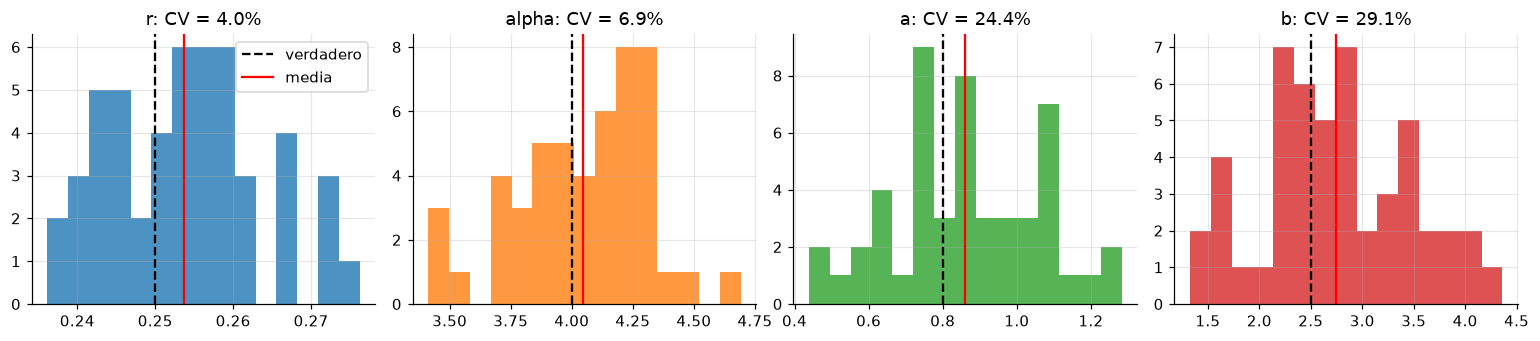

Correlación entre estimados:
          r  alpha     a     b
r      1.00   0.73 -0.08 -0.01
alpha  0.73   1.00 -0.24 -0.15
a     -0.08  -0.24  1.00  0.93
b     -0.01  -0.15  0.93  1.00

Fracción media de clientes con x=0 en las simulaciones: 0.571


In [8]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for i, c in enumerate(["r", "alpha", "a", "b"]):
    ax[i].hist(est[c], bins=15, color=f"C{i}", alpha=0.8)
    ax[i].axvline(VERDAD[i], color="k", ls="--", label="verdadero")
    ax[i].axvline(est[c].mean(), color="red", label="media")
    ax[i].set_title(f"{c}: CV = {100 * est[c].std() / VERDAD[i]:.1f}%")
ax[0].legend()
guardar(fig, "1_3_simulacion")
print("Correlación entre estimados:")
print(est[["r", "alpha", "a", "b"]].corr().round(2))
print(f"\nFracción media de clientes con x=0 en las simulaciones: {est['frac_x0'].mean():.3f}")

**1.3 Respuesta.** Sí recuperamos los parámetros: las medias de los 50
estimados quedan a menos de un error estándar del valor verdadero en los
cuatro casos y los intervalos $\pm1.96$ desviaciones cubren el valor
verdadero entre 92% y 96% de las veces. (El pequeño sesgo positivo de
$a$ y $b$, de 7–10%, es el sesgo de muestra finita típico del MLE de una
beta; es menos de medio error estándar.) Además, el chequeo de Monte Carlo
de arriba confirma que la fórmula cerrada de 1.2 es la integral de 1.1.

**¿Qué se estima con más precisión?** $r$ y $\alpha$ (CV de 4% y 7%) mucho
mejor que $a$ y $b$ (CV de 24% y 29%). Razones:

1. **Información.** Todos los clientes informan sobre el proceso de compra
   ($x$ y $T$ dicen cuánto compran), pero como mostramos en 1.2, los
   clientes con $x=0$ (57% en la simulación) no aportan *nada* sobre $(a,b)$.
   La muerte solo se aprende de los recompradores, y de forma indirecta: por
   el silencio $T-t_x$ después de su última compra, que también podría
   deberse a una $\lambda$ baja.
2. **Identificación débil de la forma de la beta.** $a$ y $b$ están muy
   correlacionados entre simulaciones (0.93): la media $a/(a+b)$ se estima
   bien (CV 7%), pero la *dispersión* de la beta (qué tan distintos son los
   clientes en su $p$) se confunde fácilmente con cambiar $a$ y $b$ juntos.
   Igual, $r$ y $\alpha$ están correlacionados (0.73) y su cociente
   $r/\alpha$, la tasa media, tiene CV de 5%.

Moraleja: los resultados que dependen del *promedio* (tasa media, $E[p]$,
pronósticos agregados) son robustos; los que dependen de la *forma* de la
heterogeneidad en la muerte merecen más cautela.

---
## Parte 2: ajuste a CDNOW

### 2.1 Estimación

In [9]:
ajuste = bgnbd.fit(x, tx, T)
P = ajuste["params"]
r, alpha, a, b = P
art = np.array([0.243, 4.414, 0.793, 2.426])
tabla(pd.DataFrame({"nuestro": np.r_[P, ajuste["loglik"]],
                    "artículo": np.r_[art, -9582.4]},
                   index=["r", "alpha", "a", "b", "log-verosimilitud"]).round(4),
      "2_1_estimados")

,nuestro,artículo
r,0.2426,0.243
alpha,4.4136,4.414
a,0.7929,0.793
b,2.4259,2.426
log-verosimilitud,-9582.4292,-9582.400


Arranques múltiples: todos los arranques razonables llegan al mismo óptimo.
Si alguno se queda en una cota (por ejemplo $a\approx 0$ o $b$ enorme) es un
optimizador perdido, no un estimado, y su log-verosimilitud lo delata.

In [10]:
pd.DataFrame([np.r_[p, l] for p, l in ajuste["runs"]],
             columns=["r", "alpha", "a", "b", "loglik"]).round(4)

,r,alpha,a,b,loglik
0,0.2426,4.4136,0.7929,2.4259,-9582.4292
1,0.2426,4.4136,0.7929,2.4258,-9582.4292
2,0.2426,4.4136,0.7929,2.4260,-9582.4292
3,0.2426,4.4136,0.7929,2.4259,-9582.4292
4,0.2426,4.4136,0.7930,2.4263,-9582.4292
5,0.3799,11.8101,0.0000,21461.8247,-9763.2297


### 2.2 Interpretación de los parámetros

Tasa media de compra de un cliente activo  E[λ] = r/α = 0.0550 por semana = 2.86 por año
Desv. est. de λ = sqrt(r)/α = 0.1116;  CV(λ) = 1/sqrt(r) = 2.03
Mediana de λ = 0.00902 por semana
P(λ < 0.01/semana) = 0.512
Prob. media de morir tras una compra E[p] = a/(a+b) = 0.2463
Mediana de p = 0.1912;  desv. est. de p = 0.2098
Vida esperada (en compras repetidas) de un cliente típico ~ 1/E[p] = 4.1


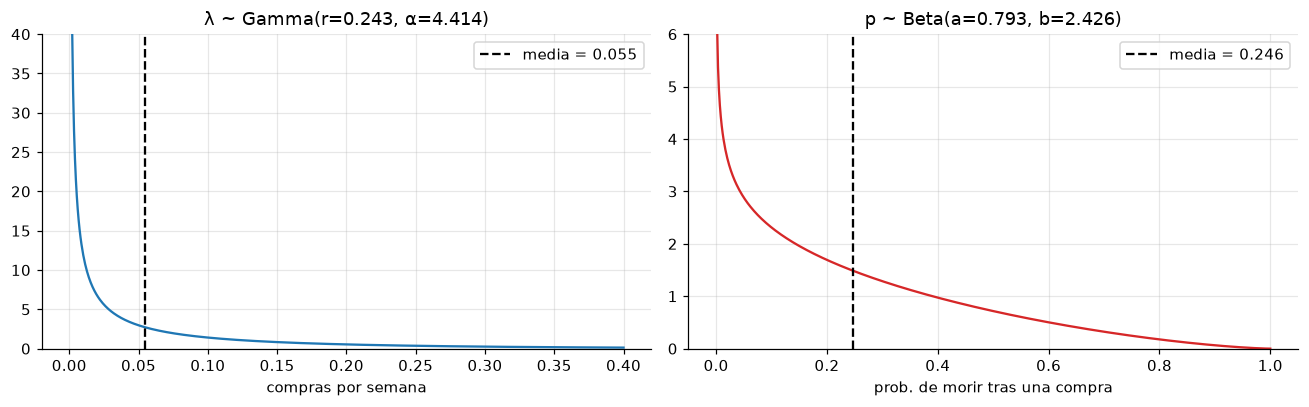

In [11]:
media_lam = r / alpha
media_p = a / (a + b)
print(f"Tasa media de compra de un cliente activo  E[λ] = r/α = {media_lam:.4f} por semana "
      f"= {52 * media_lam:.2f} por año")
print(f"Desv. est. de λ = sqrt(r)/α = {np.sqrt(r) / alpha:.4f};  CV(λ) = 1/sqrt(r) = {1 / np.sqrt(r):.2f}")
print(f"Mediana de λ = {stats.gamma(r, scale=1 / alpha).median():.5f} por semana")
print(f"P(λ < 0.01/semana) = {stats.gamma(r, scale=1 / alpha).cdf(0.01):.3f}")
print(f"Prob. media de morir tras una compra E[p] = a/(a+b) = {media_p:.4f}")
print(f"Mediana de p = {stats.beta(a, b).median():.4f};  desv. est. de p = {stats.beta(a, b).std():.4f}")
print(f"Vida esperada (en compras repetidas) de un cliente típico ~ 1/E[p] = {1 / media_p:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
lg = np.linspace(1e-4, 0.4, 600)
ax[0].plot(lg, stats.gamma(r, scale=1 / alpha).pdf(lg), color="C0")
ax[0].axvline(media_lam, color="k", ls="--", label=f"media = {media_lam:.3f}")
ax[0].set(title=f"λ ~ Gamma(r={r:.3f}, α={alpha:.3f})", xlabel="compras por semana",
          ylim=(0, 40))
ax[0].legend()
pg = np.linspace(1e-4, 1 - 1e-4, 600)
ax[1].plot(pg, stats.beta(a, b).pdf(pg), color="C3")
ax[1].axvline(media_p, color="k", ls="--", label=f"media = {media_p:.3f}")
ax[1].set(title=f"p ~ Beta(a={a:.3f}, b={b:.3f})", xlabel="prob. de morir tras una compra",
          ylim=(0, 6))
ax[1].legend()
guardar(fig, "2_2_densidades")

**2.1 Respuesta.** Obtenemos $(r,\alpha,a,b)=(0.2426, 4.4136, 0.7929,
2.4259)$ con log-verosimilitud $-9582.43$: idénticos al artículo (0.243,
4.414, 0.793, 2.426; $-9582.4$) al redondeo. Cinco de seis arranques llegan
al mismo punto; el sexto se perdió en $a\to 0$, $b\to\infty$ con una
log-verosimilitud 181 unidades peor — exactamente el "optimizador perdido"
contra el que advierte el enunciado. Por eso siempre arrancamos desde varios
puntos y nos quedamos con el mejor.

**2.2 Respuesta.**

* **Tasa de compra de un cliente activo:** $E[\lambda]=r/\alpha=0.055$
  compras por semana, unas **2.9 compras repetidas al año**. Pero la media
  engaña: con $r=0.24<1$ la gamma tiene forma de "L", con moda en 0 y cola
  larga (CV = $1/\sqrt r$ = 2.0). La **mediana es 0.009** por semana (una
  compra cada ~2 años) y la mitad de los clientes tiene $\lambda<0.01$. Unos
  pocos clientes muy activos jalan la media hacia arriba.
* **Probabilidad de morir después de una compra:** $E[p]=a/(a+b)=0.246$. En
  promedio, uno de cada cuatro "se va" después de cada recompra, lo que da
  una vida esperada de unas 4 compras repetidas. Con $a=0.79<1$ la densidad
  de $p$ se dispara cerca de 0 (muchos clientes muy leales) pero tiene cola
  larga hacia 1 (clientes que casi seguro se van tras la siguiente compra);
  la desviación estándar (0.21) es casi igual a la media.
* **¿Qué tan parecidos son los clientes?** Muy poco. Ambas distribuciones
  están lejos de ser una punta alrededor de la media: hay muchísima
  heterogeneidad tanto en *cuánto* compran como en *cuánto duran*. Por eso un
  modelo que trata a todos igual (o la serie agregada) pierde información, y
  por eso tiene sentido hablar de "quién sigue vivo" cliente por cliente.

### 2.3 Bono: error estándar por *bootstrap* sobre clientes

Remuestreamos los 2,357 clientes con reemplazo 300 veces y reestimamos.
Como referencia agregamos también el error estándar asintótico (inversa del
hessiano numérico en log-parámetros, llevado a la escala original con el
método delta).

In [12]:
B = 300
rng = np.random.default_rng(2024)
boot = []
for _ in range(B):
    idx = rng.integers(0, len(x), len(x))
    fb = bgnbd.fit(x[idx], tx[idx], T[idx], starts=[ajuste["logparams"], np.zeros(4)])
    boot.append(fb["params"])
boot = pd.DataFrame(boot, columns=["r", "alpha", "a", "b"])


def hessiano(f, z, h=1e-4):
    k = len(z)
    H = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            ei, ej = np.eye(k)[i] * h, np.eye(k)[j] * h
            H[i, j] = (f(z + ei + ej) - f(z + ei - ej) - f(z - ei + ej) + f(z - ei - ej)) / (4 * h * h)
    return H


negll = lambda z: -bgnbd.loglik(np.exp(z), x, tx, T)
cov_log = np.linalg.inv(hessiano(negll, ajuste["logparams"]))
se_hess = P * np.sqrt(np.diag(cov_log))
# desviación de la simulación 1.3 reescalada: CV de la simulación x estimado de CDNOW
se_sim = (est[["r", "alpha", "a", "b"]].std() / VERDAD).to_numpy() * P
tabla(pd.DataFrame({
    "estimado": P,
    "EE bootstrap": boot.std().to_numpy(),
    "EE hessiano": se_hess,
    "desv. simulación 1.3": est[["r", "alpha", "a", "b"]].std().to_numpy(),
    "CV bootstrap %": 100 * boot.std().to_numpy() / P,
    "CV simulación %": 100 * (est[["r", "alpha", "a", "b"]].std() / VERDAD).to_numpy(),
    "IC 95% bootstrap": [f"[{boot[c].quantile(.025):.3f}, {boot[c].quantile(.975):.3f}]"
                         for c in boot.columns],
}, index=["r", "alpha", "a", "b"]).round(4), "2_3_bootstrap")

,estimado,EE bootstrap,EE hessiano,desv. simulación 1.3,CV bootstrap %,CV simulación %,IC 95% bootstrap
r,0.2426,0.0136,0.0126,0.0099,5.6009,3.9701,"[0.219, 0.272]"
alpha,4.4136,0.4468,0.3782,0.2742,10.1241,6.8548,"[3.667, 5.337]"
a,0.7929,0.1778,0.1857,0.1953,22.4242,24.4108,"[0.539, 1.196]"
b,2.4259,0.7145,0.7054,0.7272,29.4510,29.0881,"[1.496, 4.222]"


**2.3 Respuesta.** El *bootstrap* da errores estándar de 0.014 para $r$,
0.45 para $\alpha$, 0.18 para $a$ y 0.71 para $b$. El patrón es el mismo de
la simulación 1.3: $r$ y $\alpha$ con CV de 6–10%, $a$ y $b$ con CV de
22–29%. Para $a$ y $b$ los tres números (bootstrap, hessiano y la
dispersión de la simulación) prácticamente coinciden, lo que dice que la
simulación fue un buen ensayo del problema real.

Para $r$ y sobre todo $\alpha$, el bootstrap es más grande que el hessiano
(0.45 vs 0.38) y que la dispersión simulada. El error estándar del hessiano
y la simulación suponen que **el modelo es el verdadero**; el bootstrap no.
Que el bootstrap sea mayor sugiere que en los datos reales hay variabilidad
en el proceso de compra que el BG/NBD no captura del todo (por ejemplo
compras más regulares o más "en racimos" que un Poisson), es decir, cierta
mala especificación. Con datos reales conviene preferir el bootstrap.

---
## Parte 3: pronóstico de abajo hacia arriba y de arriba hacia abajo

### 3.1 *Bottom-up*

El cliente $i$ hizo su primera compra en la semana $s_i$ (días/7). Las
compras repetidas esperadas de toda la cohorte hasta la semana $k$ son
$\sum_i \mathbb{E}[X(k - s_i)]$ (con $\mathbb{E}[X(t)] = 0$ si $t \le 0$).

Compras repetidas en el holdout (sem 40-78): real = 1882, BG/NBD = 1664.1  (error -11.6%)
Acumulado a la semana 78: real = 4339, BG/NBD = 4165.7


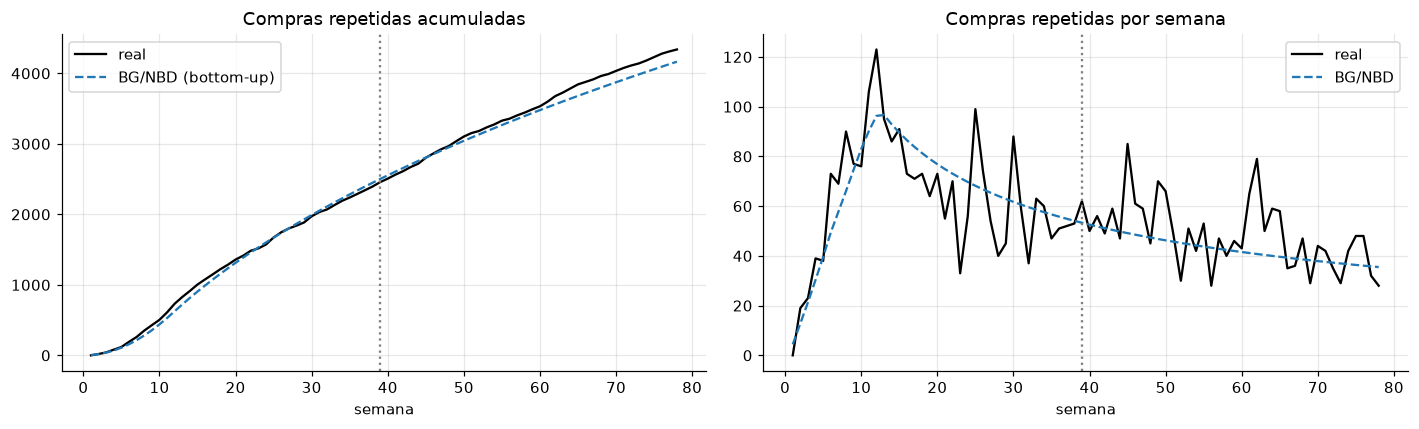

In [13]:
trans = trans.merge(d[["primera"]], left_on="id", right_index=True)
trans["repetida"] = trans["fecha"] > trans["primera"]
trans["sem"] = trans["dia"] // 7 + 1          # semana 1..78
semanas = np.arange(1, 79)
real_sem = (trans[trans["repetida"]].groupby("sem").size()
            .reindex(semanas, fill_value=0).astype(float))
real_acum = real_sem.cumsum()
t0 = d["t0"].to_numpy()
bu_acum = pd.Series([bgnbd.expected_x(k - t0, P).sum() for k in semanas], index=semanas)
bu_sem = bu_acum.diff().fillna(bu_acum.iloc[0])

hold_real = real_acum[78] - real_acum[39]
hold_bu = bu_acum[78] - bu_acum[39]
print(f"Compras repetidas en el holdout (sem 40-78): real = {hold_real:.0f}, "
      f"BG/NBD = {hold_bu:.1f}  (error {100 * (hold_bu / hold_real - 1):+.1f}%)")
print(f"Acumulado a la semana 78: real = {real_acum[78]:.0f}, BG/NBD = {bu_acum[78]:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(semanas, real_acum, "k", label="real")
ax[0].plot(semanas, bu_acum, "C0--", label="BG/NBD (bottom-up)")
ax[0].axvline(39, color="gray", ls=":")
ax[0].set(title="Compras repetidas acumuladas", xlabel="semana")
ax[0].legend()
ax[1].plot(semanas, real_sem, "k", label="real")
ax[1].plot(semanas, bu_sem, "C0--", label="BG/NBD")
ax[1].axvline(39, color="gray", ls=":")
ax[1].set(title="Compras repetidas por semana", xlabel="semana")
ax[1].legend()
guardar(fig, "3_1_bottom_up")

**3.1 Respuesta.** La curva acumulada del BG/NBD sigue muy de cerca a la
real en calibración y se va quedando un poco abajo en el *holdout*. A la
semana 78 pronostica 4,166 compras repetidas acumuladas contra 4,339 reales,
un **subpronóstico de 4.0%, exactamente lo que reporta el artículo**
("under-forecasting by ... 4%"). Medido solo en el *holdout* (semanas
40–78) el modelo pronostica 1,664 contra 1,882 reales (−11.6%): el error
relativo se ve más grande porque se calcula sobre un total más chico. En la
serie semanal se ve por qué: la serie real tiene picos (semana 45, inicios
de noviembre; semanas 49–50, la temporada navideña de diciembre; semanas
61–65, marzo de 1998) que una curva suave y sin estacionalidad no puede
reproducir, y entre las semanas 45 y 66 la serie real se mantiene casi
siempre por encima del modelo: la caída real es algo más lenta que la
predicha.

### 3.2 *Top-down*

Ahora solo vemos la serie semanal agregada de las semanas 1–39 y
pronosticamos 40–78 con métodos de la tarea de series de tiempo. Los que
dependen de una ventana se prueban con varias.

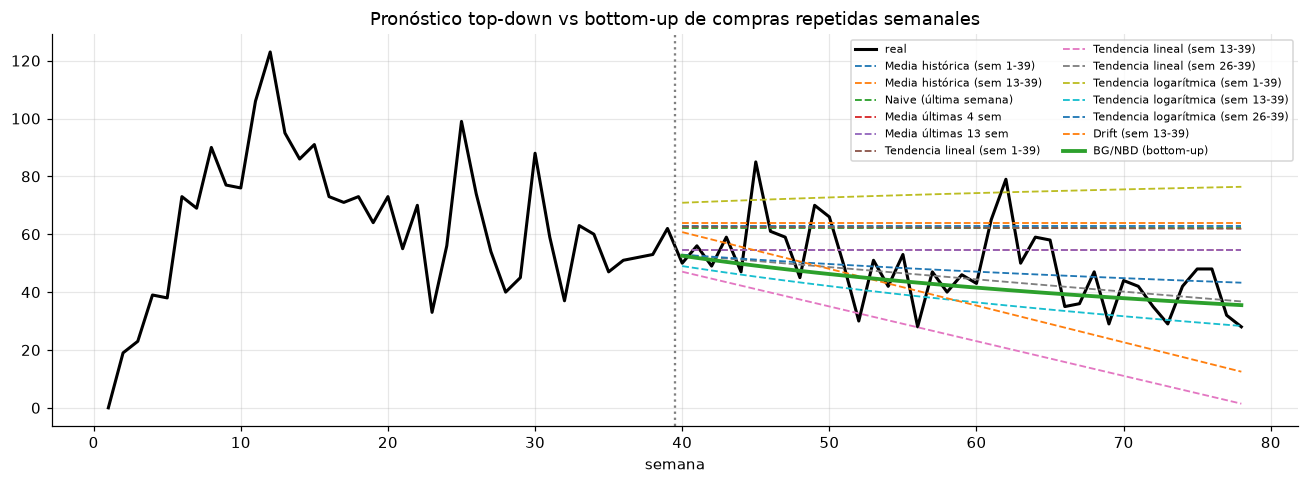

In [14]:
y = real_sem.loc[1:39].to_numpy()
h = 39
semanas_h = np.arange(40, 79)


def tendencia(y, desde):
    t = np.arange(desde, 40)
    m, c = np.polyfit(t, y[desde - 1:], 1)
    return np.maximum(m * semanas_h + c, 0)


def tendencia_log(y, desde):
    # y = c + m ln(t): la serie decae cada vez más despacio
    t = np.arange(desde, 40)
    m, c = np.polyfit(np.log(t), y[desde - 1:], 1)
    return np.maximum(m * np.log(semanas_h) + c, 0)


metodos = {
    "Media histórica (sem 1-39)": np.full(h, y.mean()),
    "Media histórica (sem 13-39)": np.full(h, y[12:].mean()),
    "Naive (última semana)": np.full(h, y[-1]),
    "Media últimas 4 sem": np.full(h, y[-4:].mean()),
    "Media últimas 13 sem": np.full(h, y[-13:].mean()),
    "Tendencia lineal (sem 1-39)": tendencia(y, 1),
    "Tendencia lineal (sem 13-39)": tendencia(y, 13),
    "Tendencia lineal (sem 26-39)": tendencia(y, 26),
    "Tendencia logarítmica (sem 1-39)": tendencia_log(y, 1),
    "Tendencia logarítmica (sem 13-39)": tendencia_log(y, 13),
    "Tendencia logarítmica (sem 26-39)": tendencia_log(y, 26),
    "Drift (sem 13-39)": np.maximum(y[-1] + (y[-1] - y[12]) / (39 - 13) * np.arange(1, h + 1), 0),
    "BG/NBD (bottom-up)": bu_sem.loc[40:78].to_numpy(),
}
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(semanas, real_sem, "k", lw=2, label="real")
for i, (nombre, f) in enumerate(metodos.items()):
    estilo = "-" if "BG" in nombre else "--"
    ax.plot(semanas_h, f, estilo, lw=2.5 if "BG" in nombre else 1.2, label=nombre)
ax.axvline(39.5, color="gray", ls=":")
ax.set(title="Pronóstico top-down vs bottom-up de compras repetidas semanales", xlabel="semana")
ax.legend(fontsize=7, ncol=2)
guardar(fig, "3_2_top_down")

### 3.3 Comparación

In [15]:
real_h = real_sem.loc[40:78].to_numpy()
comp = pd.DataFrame({
    "total holdout": {k: f.sum() for k, f in metodos.items()},
    "error %": {k: 100 * (f.sum() / real_h.sum() - 1) for k, f in metodos.items()},
    "MAE semanal": {k: np.mean(np.abs(f - real_h)) for k, f in metodos.items()},
})
comp.loc["(real)"] = [real_h.sum(), 0, 0]
tabla(comp.sort_values("MAE semanal").round(2), "3_3_comparacion")

,total holdout,error %,MAE semanal
(real),1882.00,0.00,0.00
Tendencia lineal (sem 26-39),1748.40,-7.10,9.28
Tendencia logarítmica (sem 26-39),1855.63,-1.40,9.34
BG/NBD (bottom-up),1664.14,-11.58,9.83
Tendencia logarítmica (sem 13-39),1463.97,-22.21,12.06
Media últimas 4 sem,2125.50,12.94,12.27
Media últimas 13 sem,2133.00,13.34,12.35
Drift (sem 13-39),1428.00,-24.12,15.05
Naive (última semana),2418.00,28.48,16.56
Tendencia lineal (sem 1-39),2428.37,29.03,16.73


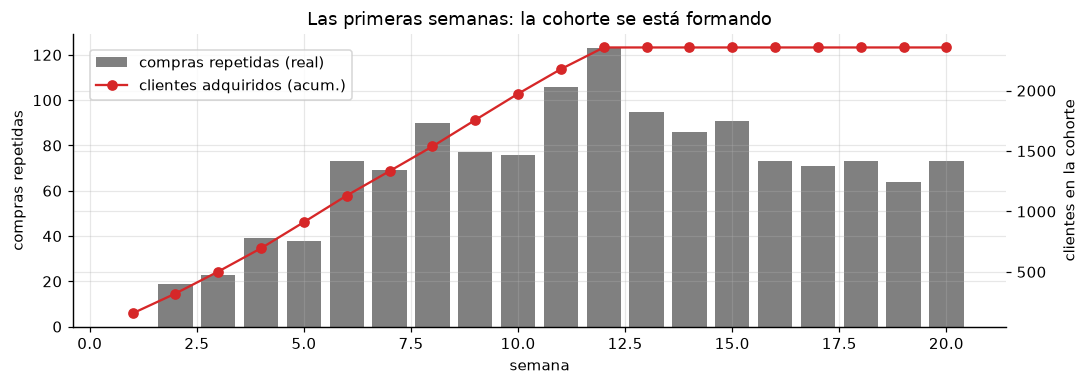

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(semanas[:20], real_sem.iloc[:20], color="gray", label="compras repetidas (real)")
ax2 = ax.twinx()
nuevos = d.groupby(np.floor(d["t0"]).astype(int) + 1).size().reindex(semanas[:20], fill_value=0)
ax2.plot(semanas[:20], nuevos.cumsum(), "C3o-", label="clientes adquiridos (acum.)")
ax.set(xlabel="semana", ylabel="compras repetidas", title="Las primeras semanas: la cohorte se está formando")
ax2.set_ylabel("clientes en la cohorte")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
guardar(fig, "3_3_primeras_semanas")

**3.3 Respuesta.**

* **¿Quién gana?** Ex post, una sola variante top-down — la tendencia lineal
  ajustada en las semanas 26–39 — tiene un MAE semanal ligeramente menor
  (9.3 vs 9.8) y un error total menor (−7% vs −12%) que el BG/NBD. Pero el
  BG/NBD es el segundo, y le gana a **todos** los demás métodos top-down.
  La tendencia logarítmica ($c + m \ln t$) con la ventana 26–39 queda casi
  empatada con la lineal (MAE 9.3) y acierta el total (−1%), pero con las
  otras ventanas pierde contra el BG/NBD.
* **Sensibilidad a la ventana:** enorme. La misma tendencia lineal da +29%
  con la ventana 1–39, −50% con la 13–39 y −7% con la 26–39; la
  logarítmica da +53%, −22% y −1% con las mismas ventanas; la media
  histórica da +31%, la naive +28%, el drift −24%. Elegir la ventana
  "ganadora" sabiendo el resultado es hacer trampa: el 30 de septiembre no
  había forma de saber cuál de estas variantes, que van de −50% a +53%,
  escoger. El BG/NBD no tiene ventanas que escoger y su error está dentro
  de lo que se puede esperar con 2,357 clientes.
* **Las primeras 12 semanas:** la cohorte **se está formando**. Los
  clientes llegaron entre la semana 1 y la 12 (gráfica de arriba), así que
  el número de clientes "en riesgo" de recomprar crece semana a semana y las
  compras repetidas suben mecánicamente. A partir de la semana 13 la cohorte
  está cerrada: ya no entra nadie y los que están se van muriendo, por eso la
  serie baja. Un método top-down solo ve una serie que sube y luego baja; no
  puede saber que la subida fue por adquisición, que la adquisición se
  detuvo, ni cuántos clientes siguen vivos. El bottom-up usa la fecha de
  primera compra de cada cliente y lo sabe por construcción.

### 3.4 Por cliente: esperanzas condicionales

In [17]:
ey39 = bgnbd.conditional_expected(39, P, x, tx, T)
grupo = np.where(x >= 7, "7+", x.astype(int).astype(str))
cond = (pd.DataFrame({"x": grupo, "E[Y(39)]": ey39, "x* real": xs})
        .groupby("x").agg(clientes=("x* real", "size"),
                          **{"BG/NBD E[Y(39)]": ("E[Y(39)]", "mean"),
                             "real x*": ("x* real", "mean")}))
cond = cond.loc[["0", "1", "2", "3", "4", "5", "6", "7+"]]
cond["error %"] = 100 * (cond["BG/NBD E[Y(39)]"] / cond["real x*"] - 1)
print(f"Suma de E[Y(39)] sobre clientes = {ey39.sum():.1f} (real {xs.sum():.0f})")
print(f"Correlación entre x* real y E[Y(39)] por cliente = {np.corrcoef(xs, ey39)[0, 1]:.3f} "
      f"(el artículo reporta 0.626)")
print(f"Grupo x=0: {xs[x == 0].sum():.0f} compras en el holdout "
      f"({100 * xs[x == 0].sum() / xs.sum():.0f}% del total)")
tabla(cond.round(3), "3_4_condicional")

Suma de E[Y(39)] sobre clientes = 1653.4 (real 1882)
Correlación entre x* real y E[Y(39)] por cliente = 0.626 (el artículo reporta 0.626)
Grupo x=0: 334 compras en el holdout (18% del total)


,clientes,BG/NBD E[Y(39)],real x*,error %
x,,,,
0,1411,0.225,0.237,-4.911
1,439,0.523,0.697,-24.949
2,214,1.044,1.393,-25.019
3,100,1.520,1.560,-2.546
4,62,2.164,2.532,-14.548
5,38,2.654,2.947,-9.959
6,29,3.504,3.862,-9.270
7+,64,6.157,6.359,-3.179


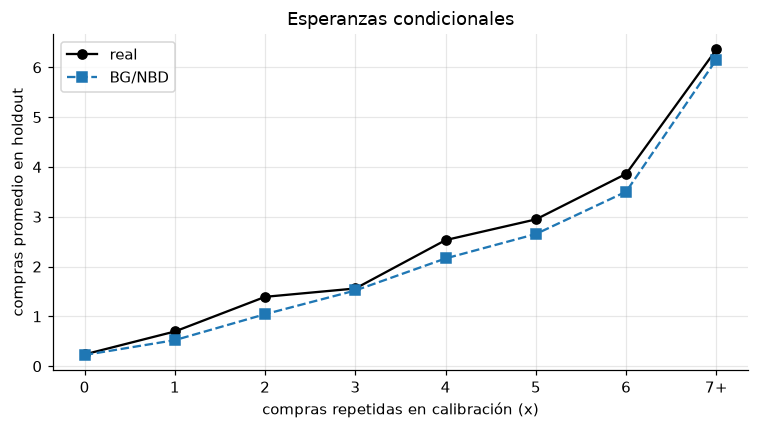

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cond.index, cond["real x*"], "ko-", label="real")
ax.plot(cond.index, cond["BG/NBD E[Y(39)]"], "C0s--", label="BG/NBD")
ax.set(xlabel="compras repetidas en calibración (x)", ylabel="compras promedio en holdout",
       title="Esperanzas condicionales")
ax.legend()
guardar(fig, "3_4_condicional")

**3.4 Respuesta.** El modelo reproduce la forma creciente de la relación
(más compras pasadas, más compras futuras) y acierta muy bien en el gran
grupo $x=0$ (0.225 pronosticado vs 0.237 real; el artículo reporta 0.23 vs
0.24) y en $x=3$ (1.52 vs 1.56, igual que en el artículo) y $7+$ (−3%).
Donde **más se equivoca es en $x=1$ y $x=2$** (−25% en ambos): el modelo
subestima a los clientes que recompraron una o dos veces; con $E[p]=0.25$
"mata" a demasiados de ellos tras su última compra. También subestima a
$x=4$ (−15%). Como casi todos los grupos quedan por debajo, el total (1,653)
queda 12% abajo. La correlación entre $x^*$ real y $E[Y(39)]$ por cliente es
0.626, y el grupo $x=0$ hace 334 compras en el *holdout* (18% del total):
ambos números son idénticos a los del artículo. Que el modelo acierte en
el grupo silencioso es importante porque es el grupo más grande.

**¿Esto lo puede hacer un top-down?** No. Un pronóstico top-down es de la
serie agregada; no tiene idea de qué clientes componen el total, así que no
puede decir cuánto va a comprar un cliente con $x=2$ comparado con uno con
$x=0$, ni asignar el pronóstico a individuos. A lo sumo podría repartir el
total proporcionalmente, lo cual supone que todos son iguales —
exactamente lo que la Parte 2 mostró que no es cierto.

---
## Parte 4: ¿quién sigue vivo?

### 4.1 P(vivo) como clasificador de $Z$

In [19]:
Z = (xs >= 1).astype(int)
palive = bgnbd.p_alive(P, x, tx, T)
print(f"Tasa base: P(Z=1) = {Z.mean():.4f}  ({Z.sum()} de {len(Z)} clientes compran en el holdout)")
cm = confusion_matrix(Z, (palive >= 0.5).astype(int))
print("\nMatriz de confusión (umbral 0.5), filas = real, columnas = predicho:")
print(pd.DataFrame(cm, index=["Z=0", "Z=1"], columns=["pred 0", "pred 1"]))
auc_palive = roc_auc_score(Z, palive)
print(f"\nAUC de P(vivo) = {auc_palive:.4f}")
print(f"Exactitud con umbral 0.5 = {np.trace(cm) / cm.sum():.3f}   vs. predecir siempre 0 = {1 - Z.mean():.3f}")

Tasa base: P(Z=1) = 0.2902  (684 de 2357 clientes compran en el holdout)

Matriz de confusión (umbral 0.5), filas = real, columnas = predicho:
     pred 0  pred 1
Z=0     254    1419
Z=1     139     545

AUC de P(vivo) = 0.3158
Exactitud con umbral 0.5 = 0.339   vs. predecir siempre 0 = 0.710


### 4.2 ¿Por qué se ve raro?

In [20]:
print(f"P(vivo) para clientes con x=0: min = {palive[x == 0].min():.4f}, max = {palive[x == 0].max():.4f}")
print(f"Clientes con x=0: {np.sum(x == 0)}; de ellos compraron en el holdout: {Z[x == 0].mean():.3f}")
print(f"Clientes con x>0: {np.sum(x > 0)}; de ellos compraron en el holdout: {Z[x > 0].mean():.3f}")
print(f"P(vivo) promedio en x>0: {palive[x > 0].mean():.3f}")
print(f"AUC de P(vivo) solo entre clientes con x>0: {roc_auc_score(Z[x > 0], palive[x > 0]):.4f}")

P(vivo) para clientes con x=0: min = 1.0000, max = 1.0000
Clientes con x=0: 1411; de ellos compraron en el holdout: 0.137
Clientes con x>0: 946; de ellos compraron en el holdout: 0.519
P(vivo) promedio en x>0: 0.535
AUC de P(vivo) solo entre clientes con x>0: 0.6984


**4.1 Respuesta.** La tasa base es 29.0%: 684 de los 2,357 clientes
compraron al menos una vez en el *holdout*. Usando $P(\text{vivo})\ge 0.5$
como regla, el modelo declara "vivos" a 1,964 clientes, de los cuales solo
545 compran; la exactitud es 34%, muy por debajo del 71% que se obtiene
diciendo "nadie compra". El **AUC es 0.316, peor que tirar una moneda**: la
curva ROC queda debajo de la diagonal.

**4.2 Respuesta.** La explicación está en la pieza de muerte del BG/NBD.
Para un cliente con $x=0$, $P(\text{vivo})=1$ *exactamente*: como solo se
puede morir justo después de una compra repetida, quien nunca recompró no
ha tenido oportunidad de morir (en la fórmula, el término con
$\delta_{x>0}$ desaparece y queda $[1+0]^{-1}=1$). Pero esos 1,411 clientes
son justamente los menos propensos a comprar: solo **13.7%** de ellos compró
en el *holdout*, contra 51.9% de los que tenían $x>0$. El clasificador pone
en el primer lugar del ranking, empatados con probabilidad 1, al grupo con
menor tasa de compra; eso es lo que voltea la ROC (el tramo recto largo de
la curva naranja es ese bloque de empates). Entre los clientes con $x>0$,
donde $P(\text{vivo})$ sí distingue, su AUC es 0.70.

La lección: **"vivo" no es "va a comprar"**. Un cliente con $x=0$ puede
estar vivo y tener una $\lambda$ minúscula; para la pregunta "¿comprará?"
hay que combinar la probabilidad de estar vivo con la probabilidad de que,
estando vivo, compre en el horizonte.

### 4.3 La probabilidad correcta

$Z=0$ ocurre si (a) el cliente está muerto en $T$, o (b) está vivo en $T$ y
no compra en $(T, T+\tau]$. Entonces
$$\mathbb{P}(Z=1\mid x,t_x,T)=\mathbb{P}(\text{vivo}\mid x,t_x,T)\cdot\big[1-\mathbb{P}(\text{0 compras en }\tau\mid\text{vivo},x,t_x,T)\big].$$

1. **Un vivo que no compra sigue vivo.** En el BG/NBD solo se muere justo
   después de una compra; mientras no compre, no hay oportunidad de morir.
   Por eso "cero compras en $(T,T+\tau]$" para un cliente vivo es
   simplemente el evento de Poisson "cero llegadas en $\tau$", con
   probabilidad $e^{-\lambda\tau}$. (Si compra y luego muere, igual $Z=1$.)
2. **Posterior de $\lambda$ dado que está vivo.** Por Bayes,
   $g(\lambda\mid\text{vivo},x,t_x,T)\propto g(\lambda)\,\mathbb{P}(\text{datos},\text{vivo}\mid\lambda)$.
   La parte de $\lambda$ en la historia "vivo" de 1.1 es $\lambda^x e^{-\lambda T}$
   (la parte $(1-p)^x$ no depende de $\lambda$ y por la independencia (v) se
   va en la constante). Entonces
   $g(\lambda\mid\cdot)\propto\lambda^{r-1}e^{-\alpha\lambda}\lambda^x e^{-\lambda T}=\lambda^{r+x-1}e^{-(\alpha+T)\lambda}$,
   es decir, $\lambda\mid\text{vivo}\sim\text{Gamma}(r+x,\alpha+T)$.
3. **Mezcla gamma–Poisson para cero compras:**
$$\mathbb{P}(\text{0 en }\tau\mid\text{vivo})=\int_0^\infty e^{-\lambda\tau}\frac{(\alpha+T)^{r+x}\lambda^{r+x-1}e^{-(\alpha+T)\lambda}}{\Gamma(r+x)}d\lambda=\left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}.$$

Juntando,
$$\boxed{\mathbb{P}(Z=1\mid x,t_x,T)=\mathbb{P}(\text{vivo}\mid x,t_x,T)\left[1-\left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}\right]}$$
Para $x=0$ el primer factor vale 1, pero el segundo es pequeño cuando
$r/(\alpha+T)$ — la tasa esperada a posteriori — es baja: eso arregla el
problema de 4.2.

In [21]:
pz = bgnbd.p_buy(39, P, x, tx, T)
print(f"P(Z=1) promedio = {pz.mean():.4f}   vs. tasa real = {Z.mean():.4f}")
print(f"Suma de P(Z=1) = {pz.sum():.1f} clientes esperados vs. {Z.sum()} reales")
print(f"P(Z=1) para x=0: promedio {pz[x == 0].mean():.4f} (real {Z[x == 0].mean():.4f})")

P(Z=1) promedio = 0.2618   vs. tasa real = 0.2902
Suma de P(Z=1) = 617.0 clientes esperados vs. 684 reales
P(Z=1) para x=0: promedio 0.1605 (real 0.1368)


### 4.4 Verificación por simulación

Simulamos 20 copias de la cohorte (47,140 clientes) con los parámetros
estimados y los $T$ reales, 39 semanas de calibración + 39 de *holdout*.
Calculamos $\mathbb{P}(Z=1)$ con la fórmula a partir de lo que cada cliente
simulado hizo en calibración y comparamos por deciles con la fracción que
efectivamente compró en el *holdout* simulado.

In [22]:
rng = np.random.default_rng(44)
Trep = np.tile(T, 20)
sx, stx, sT, sxh, svivo = bgnbd.simulate(P, Trep, rng, holdout=39)
spz = bgnbd.p_buy(39, P, sx, stx, sT)
spa = bgnbd.p_alive(P, sx, stx, sT)
sZ = (sxh >= 1).astype(int)
dec = pd.qcut(pd.Series(spz).rank(method="first"), 10, labels=range(1, 11))
sim44 = (pd.DataFrame({"decil": dec, "fórmula P(Z=1)": spz, "simulado": sZ})
         .groupby("decil", observed=True).mean())
print(f"Global: fórmula = {spz.mean():.4f}, simulado = {sZ.mean():.4f}")
print(f"P(vivo) promedio por fórmula = {spa.mean():.4f}; fracción realmente viva en T = {svivo.mean():.4f}")
tabla(sim44.round(4), "4_4_simulacion")

Global: fórmula = 0.2618, simulado = 0.2614
P(vivo) promedio por fórmula = 0.8119; fracción realmente viva en T = 0.8121


,fórmula P(Z=1),simulado
decil,,
1,0.1198,0.1209
2,0.1499,0.1491
3,0.1550,0.1572
4,0.1599,0.1606
5,0.1652,0.1655
6,0.1706,0.1663
7,0.1860,0.1913
8,0.3119,0.3129
9,0.4548,0.4419


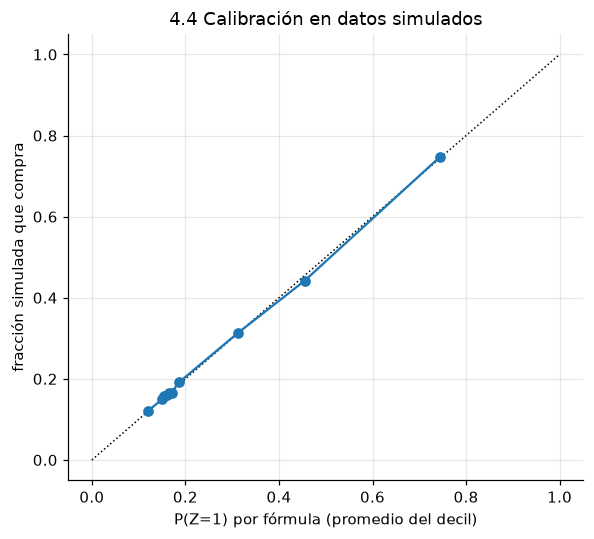

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.plot(sim44["fórmula P(Z=1)"], sim44["simulado"], "C0o-")
ax.set(xlabel="P(Z=1) por fórmula (promedio del decil)", ylabel="fracción simulada que compra",
       title="4.4 Calibración en datos simulados")
guardar(fig, "4_4_simulacion")

### 4.5 $\mathbb{P}(Z=1)$ en los datos reales

In [24]:
def calib_deciles(p, z):
    dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=range(1, 11))
    return (pd.DataFrame({"decil": dec, "predicho": p, "real": z})
            .groupby("decil", observed=True).mean())


cal45 = calib_deciles(pz, Z)
brier_m = brier_score_loss(Z, pz)
brier_base = brier_score_loss(Z, np.full(len(Z), Z.mean()))
res45 = pd.DataFrame({
    "AUC": {"P(Z=1) BG/NBD": roc_auc_score(Z, pz), "P(vivo) BG/NBD": auc_palive,
            "recencia t_x": roc_auc_score(Z, tx), "frecuencia x": roc_auc_score(Z, x)},
    "Brier": {"P(Z=1) BG/NBD": brier_m, "P(vivo) BG/NBD": brier_score_loss(Z, palive),
              "recencia t_x": np.nan, "frecuencia x": np.nan},
})
res45.loc["tasa base para todos"] = [0.5, brier_base]
print(f"Brier skill score vs tasa base: {1 - brier_m / brier_base:.3f}")
tabla(res45.round(4), "4_5_metricas")

Brier skill score vs tasa base: 0.217


,AUC,Brier
P(Z=1) BG/NBD,0.7569,0.1612
P(vivo) BG/NBD,0.3158,0.6083
recencia t_x,0.7632,NaN
frecuencia x,0.7576,NaN
tasa base para todos,0.5000,0.2060


       predicho    real
decil                  
1        0.1220  0.1992
2        0.1498  0.0975
3        0.1549  0.1362
4        0.1597  0.1144
5        0.1650  0.1610
6        0.1704  0.1702
7        0.1813  0.2373
8        0.3043  0.4383
9        0.4674  0.5339
10       0.7423  0.8136


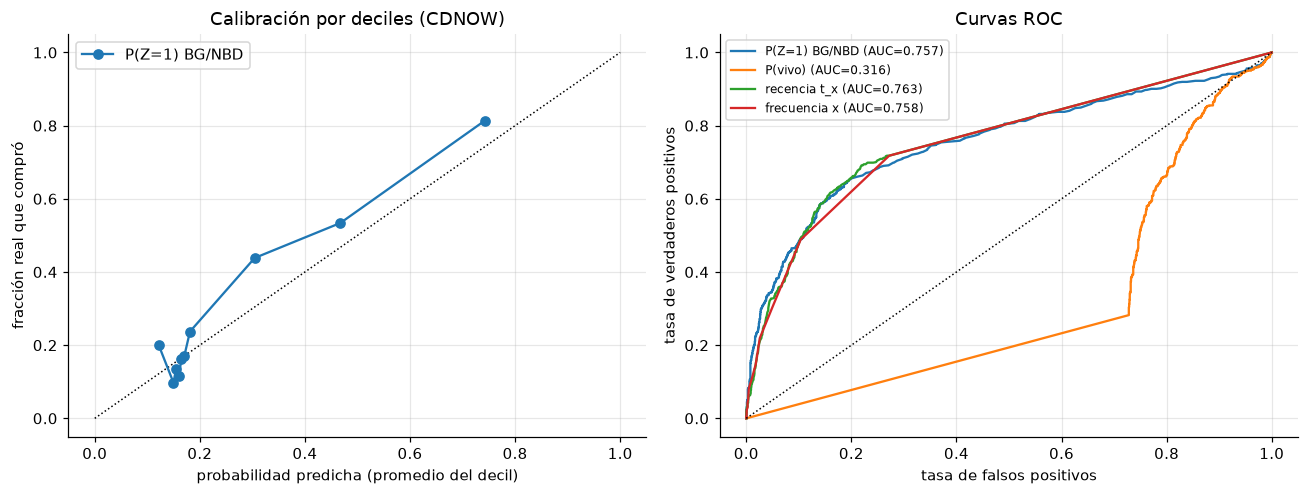

In [25]:
print(cal45.round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].plot(cal45["predicho"], cal45["real"], "C0o-", label="P(Z=1) BG/NBD")
ax[0].set(xlabel="probabilidad predicha (promedio del decil)", ylabel="fracción real que compró",
          title="Calibración por deciles (CDNOW)")
ax[0].legend()
for nombre, s in [("P(Z=1) BG/NBD", pz), ("P(vivo)", palive), ("recencia t_x", tx), ("frecuencia x", x)]:
    fpr, tpr, _ = roc_curve(Z, s)
    ax[1].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(Z, s):.3f})")
ax[1].plot([0, 1], [0, 1], "k:", lw=1)
ax[1].set(xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos", title="Curvas ROC")
ax[1].legend(fontsize=8)
guardar(fig, "4_5_calibracion_roc")

**4.4 Respuesta.** En los datos simulados con el propio modelo, la fórmula
está perfectamente calibrada: en cada decil, la probabilidad promedio de la
fórmula y la fracción simulada que compra difieren en a lo sumo 0.013
(global: 0.2618 vs 0.2614). También la $P(\text{vivo})$ promedio coincide
con la fracción realmente viva en $T$ (0.812 vs 0.812). La fórmula de 4.3
está bien derivada y bien programada.

**4.5 Respuesta.** En los datos reales:

* **AUC:** $P(Z=1)$ = 0.757, recencia $t_x$ = 0.763, frecuencia $x$ = 0.758.
  Siendo honestos: **el modelo no ordena a los clientes mejor que la
  recencia sola** (ni que la frecuencia sola); las tres ROC están casi
  encimadas. Con datos tan escasos ($x$ y $t_x$ tienen muchísimos empates,
  60% de los clientes tienen $x=0$, $t_x=0$) hay poco margen para ordenar
  mejor.
* **Brier:** 0.161 contra 0.206 de predecir la tasa base para todos (un
  *skill score* de 22%). La curva de calibración sigue a la diagonal en
  términos generales, pero el modelo **subestima** en los deciles altos (por
  ejemplo 0.30 predicho vs 0.44 real en el decil 8) y en el decil más bajo
  (0.12 vs 0.20) — este decil son recompradores con mucho silencio a quienes
  el BG/NBD "mató" con demasiada confianza. Globalmente predice 26.2% vs
  29.0% real, coherente con el −12% del total en la Parte 3.

**¿Qué ofrece el modelo que no ofrecen $t_x$ o $x$?** (1) **Probabilidades**,
no solo un orden: se puede decir "esperamos que compren 617 clientes" o
calcular un valor esperado de una promoción; $t_x$ no tiene unidades de
probabilidad. (2) **Cualquier horizonte** $\tau$ sin reentrenar nada. (3)
**Combinación coherente** de recencia, frecuencia y edad $T$: dos clientes
con el mismo $t_x$ pero distinta $x$ o distinta $T$ reciben probabilidades
distintas y con sentido. (4) Funciona **sin etiquetas**: se ajustó sin ver
un solo dato del *holdout*. (5) Además de quién compra, dice **cuánto**
($E[Y(\tau)]$) y el total de la base. Si lo único que importa es un orden
para el mismo horizonte, la recencia es casi igual de buena y mucho más
barata.

### 4.6 Otro miembro de la familia: MBG/NBD

In [26]:
aj_m = mbgnbd.fit(x, tx, T)
Pm = aj_m["params"]
pa_m = mbgnbd.p_alive(Pm, x, tx, T)
pz_m = mbgnbd.p_buy(39, Pm, x, tx, T)
bu_m = pd.Series([mbgnbd.expected_x(k - t0, Pm).sum() for k in semanas], index=semanas)
hold_bu_m = bu_m[78] - bu_m[39]
cond_m = mbgnbd.conditional_expected(39, Pm, x, tx, T)
res46 = pd.DataFrame({
    "BG/NBD": {"r": P[0], "alpha": P[1], "a": P[2], "b": P[3], "log-verosimilitud": ajuste["loglik"],
               "P(vivo) medio, x=0": palive[x == 0].mean(),
               "AUC P(vivo)": auc_palive, "AUC P(Z=1)": roc_auc_score(Z, pz),
               "Brier P(Z=1)": brier_m, "media P(Z=1)": pz.mean(),
               "holdout total (bottom-up)": hold_bu, "holdout total (suma E[Y(39)])": ey39.sum()},
    "MBG/NBD": {"r": Pm[0], "alpha": Pm[1], "a": Pm[2], "b": Pm[3], "log-verosimilitud": aj_m["loglik"],
                "P(vivo) medio, x=0": pa_m[x == 0].mean(),
                "AUC P(vivo)": roc_auc_score(Z, pa_m), "AUC P(Z=1)": roc_auc_score(Z, pz_m),
                "Brier P(Z=1)": brier_score_loss(Z, pz_m), "media P(Z=1)": pz_m.mean(),
                "holdout total (bottom-up)": hold_bu_m, "holdout total (suma E[Y(39)])": cond_m.sum()},
})
res46["real"] = np.nan
res46.loc["media P(Z=1)", "real"] = Z.mean()
res46.loc["holdout total (bottom-up)", "real"] = hold_real
res46.loc["holdout total (suma E[Y(39)])", "real"] = xs.sum()
tabla(res46.round(4), "4_6_mbgnbd")

,BG/NBD,MBG/NBD,real
r,0.2426,0.5248,NaN
alpha,4.4136,6.1831,NaN
a,0.7929,0.8914,NaN
b,2.4259,1.6140,NaN
log-verosimilitud,-9582.4292,-9582.1357,NaN
"P(vivo) medio, x=0",1.0000,0.4088,NaN
AUC P(vivo),0.3158,0.6866,NaN
AUC P(Z=1),0.7569,0.7601,NaN
Brier P(Z=1),0.1612,0.1614,NaN
media P(Z=1),0.2618,0.2400,0.2902


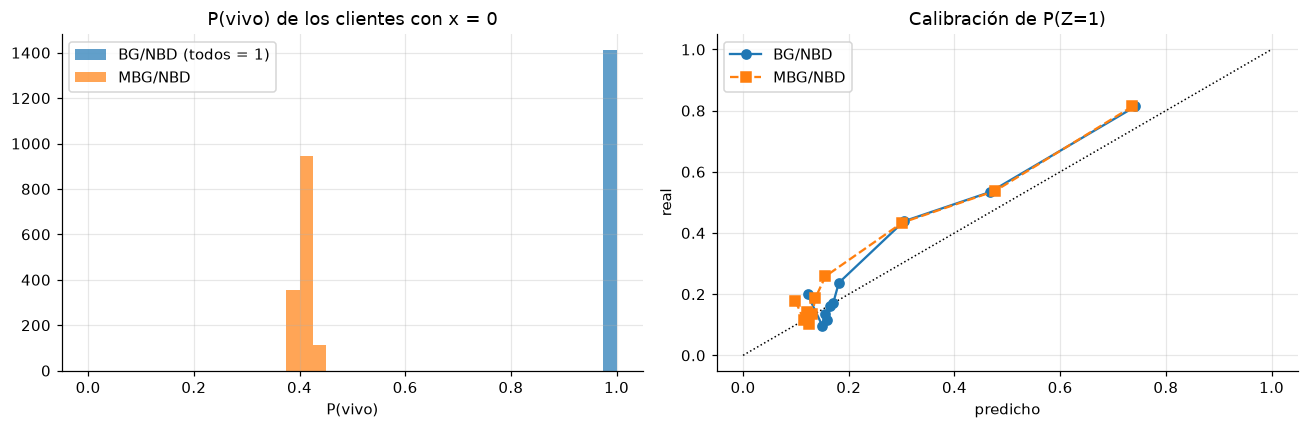

Correlación de rangos (Spearman) entre P(Z=1) BG y MBG: 0.9768


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1.0001, 41)
ax[0].hist(palive[x == 0], bins=bins, alpha=0.7, label="BG/NBD (todos = 1)")
ax[0].hist(pa_m[x == 0], bins=bins, alpha=0.7, label="MBG/NBD")
ax[0].set(title="P(vivo) de los clientes con x = 0", xlabel="P(vivo)")
ax[0].legend()
cal_m = calib_deciles(pz_m, Z)
ax[1].plot([0, 1], [0, 1], "k:", lw=1)
ax[1].plot(cal45["predicho"], cal45["real"], "C0o-", label="BG/NBD")
ax[1].plot(cal_m["predicho"], cal_m["real"], "C1s--", label="MBG/NBD")
ax[1].set(title="Calibración de P(Z=1)", xlabel="predicho", ylabel="real")
ax[1].legend()
guardar(fig, "4_6_mbgnbd")
print(f"Correlación de rangos (Spearman) entre P(Z=1) BG y MBG: {stats.spearmanr(pz, pz_m)[0]:.4f}")

**4.6 Respuesta.**

* **Ajuste:** MBG/NBD $(r,\alpha,a,b)=(0.525, 6.18, 0.891, 1.614)$ con
  log-verosimilitud $-9582.14$, apenas 0.29 mejor que el BG/NBD (mismo
  número de parámetros): para fines prácticos, empatan. Los parámetros sí
  cambian bastante: como ahora los clientes pueden morir tras su primera
  compra, la beta pone más masa en $p$ alto ($E[p]=0.36$) y la gamma se
  vuelve menos dispersa ($r$ sube de 0.24 a 0.52).
* **$P(\text{vivo})$ para $x=0$:** pasa de 1 a **0.41 en promedio**. El
  MBG/NBD reconoce que alguien que compró una vez y nunca volvió bien pudo
  haberse ido justo después. Con eso el AUC de $P(\text{vivo})$ pasa de
  0.316 a 0.687: ya no está volteado.
* **$P(Z=1)$:** AUC 0.760 vs 0.757, Brier 0.1614 vs 0.1612; el orden de los
  clientes es casi el mismo (correlación de Spearman 0.977). La fórmula de
  4.3 **sigue valiendo** porque su derivación solo usó dos hechos que el
  MBG/NBD conserva: (1) la muerte solo ocurre justo después de una compra,
  así que un cliente vivo que no compra sigue vivo; y (2) dado que está
  vivo, la parte de $\lambda$ de la verosimilitud sigue siendo
  $\lambda^x e^{-\lambda T}$, así que la posterior es $\text{Gamma}(r+x,\alpha+T)$.
  Lo único que cambia es la $P(\text{vivo})$ que multiplica.
* **Total del *holdout*:** el MBG/NBD pronostica 1,572 (−16%), peor que el
  BG/NBD (1,664, −12%); su probabilidad media de compra también queda más
  lejos (24.0% vs 26.2%, real 29.0%).

**¿Con cuál nos quedamos para decidir a quién mandar una promoción?** Para
esa decisión lo que importa es el **orden por $P(Z=1)$** (o por compras
esperadas), no $P(\text{vivo})$, y en eso los dos modelos son
prácticamente intercambiables. Desempatamos así: si el gerente va a ver un
"score de vida", usaríamos el **MBG/NBD**, porque su $P(\text{vivo})$ tiene
sentido para los clientes de una sola compra (decirle al gerente que el 60%
de su base está "viva con certeza" es engañoso). Si además hay que
presupuestar cuántas compras generará la campaña, el BG/NBD pronosticó
mejor los niveles en estos datos. Esa es la moraleja del enunciado: el
supuesto sobre *cuándo* se muere uno cambia mucho $P(\text{vivo})$ y poco
las decisiones que se toman con $P(Z=1)$.

---
## Parte 5: Online Retail

Usamos la función `limpiar` (misma lógica que en la tarea de series de
tiempo): quitamos duplicados exactos, códigos que no son productos (envío
`POST`/`DOT`, comisiones, ajustes, `M`anual, descuentos...), precios no
positivos, y conservamos las devoluciones para calcular la venta **neta**.
Nos quedamos con líneas con `CustomerID`. Una transacción es un día con
venta neta positiva de un cliente.

In [28]:
print(inspect.getsource(data.limpiar))
d5, trans5 = data.retail_rfm()
x5, tx5, T5, xs5 = (d5[c].to_numpy(float) for c in ["x", "tx", "T", "x_star"])
hold5 = (data.RETAIL_FIN_HOLD - data.RETAIL_FIN_CAL).days / 7
print(f"Transacciones cliente-día: {len(trans5):,}  |  cohorte de calibración: {len(d5):,} clientes")
print(f"Holdout: {hold5:.0f} semanas;  x=0 en calibración: {(x5 == 0).mean():.3f}")
print(d5[["x", "tx", "T", "x_star"]].describe().round(2))

def limpiar(df):
    """Limpieza de Online Retail (la misma lógica de la tarea de series).

    - quita duplicados exactos,
    - quita códigos que no son productos (envío, comisiones, ajustes...),
    - quita precios <= 0,
    - conserva las devoluciones (facturas 'C') para poder calcular venta neta,
    - agrega la venta de la línea y la fecha (sin hora).
    """
    df = df.drop_duplicates().copy()
    df["StockCode"] = df["StockCode"].astype(str).str.strip()
    df = df[~df["StockCode"].isin(NO_PRODUCTO)]
    df = df[df["UnitPrice"] > 0]
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    df["fecha"] = df["InvoiceDate"].dt.normalize()
    df["venta"] = df["Quantity"] * df["UnitPrice"]
    df["cancelada"] = df["InvoiceNo"].astype(str).str.startswith("C")
    return df



Transacciones cliente-día: 16,550  |  cohorte de calibración: 2,957 clientes
Holdout: 23 semanas;  x=0 en calibración: 0.480
             x       tx        T   x_star
count  2957.00  2957.00  2957.00  2957.00
mean      1.66     8.51    18.70     2.13
std       3.57    10.06     8.99     3.55
min       0.00     0.00     0.00     0.00
25%       0.00     0.00    11.86     0.00
50%       1.00     2.71    19.29     1.00
75%       2.00    16.71    28.14     3.00
max      58.00    30.14    30.14    70.00


### 5.1 Ajuste

In [29]:
aj5 = bgnbd.fit(x5, tx5, T5)
P5 = aj5["params"]
print("Estimados BG/NBD:", dict(zip(bgnbd.PARAMS, P5.round(6))), " loglik =", round(aj5["loglik"], 3))
print(f"¿Algún log-parámetro en la cota ±10? {aj5['en_cota']}")
print(f"E[p] = a/(a+b) = {P5[2] / (P5[2] + P5[3]):.2e}")
print(pd.DataFrame([np.r_[p, l] for p, l in aj5["runs"]], columns=["r", "alpha", "a", "b", "loglik"]))


# NBD puro (nadie se muere): el BG/NBD con p = 0
def nbd_ll(z, x, T):
    r_, al_ = np.exp(z)
    return np.sum(gammaln(r_ + x) - gammaln(r_) + r_ * np.log(al_) - (r_ + x) * np.log(al_ + T))


nbd5 = minimize(lambda z: -nbd_ll(z, x5, T5), np.zeros(2), method="Nelder-Mead")
print(f"\nNBD (sin muerte): r = {np.exp(nbd5.x[0]):.4f}, alpha = {np.exp(nbd5.x[1]):.4f}, loglik = {-nbd5.fun:.3f}")

# Perfil de la verosimilitud en E[p]: fijamos la media de p y maximizamos el resto
perfil = []
for mp in [1e-6, 1e-3, 0.01, 0.02, 0.05, 0.1, 0.2]:
    def nll_fijo(z, mp=mp):
        r_, al_, phi = np.exp(z)            # phi = a + b
        return -bgnbd.loglik([r_, al_, mp * phi, (1 - mp) * phi], x5, tx5, T5)
    rr = min((minimize(nll_fijo, s, method="Nelder-Mead", options={"maxiter": 4000})
              for s in [np.r_[np.log(P5[:2]), 0.0], np.r_[np.log(P5[:2]), 3.0]]), key=lambda q: q.fun)
    perfil.append({"E[p] fijo": mp, "loglik máx": -rr.fun, "Δ vs óptimo": -rr.fun - aj5["loglik"]})
tabla(pd.DataFrame(perfil).round(3), "5_1_perfil")

Estimados BG/NBD: {'r': np.float64(0.739973), 'alpha': np.float64(9.169155), 'a': np.float64(2e-06), 'b': np.float64(90890.895321)}  loglik = -15107.235
¿Algún log-parámetro en la cota ±10? True
E[p] = a/(a+b) = 2.54e-11
        r   alpha           a           b      loglik
0  0.7400  9.1695  4.5400e-05   6398.6159 -15107.2349
1  0.7443  9.2253  1.4227e-03    709.4802 -15107.2457
2  0.7395  9.1636  7.1804e-05    323.9390 -15107.2352
3  0.7399  9.1651  1.1800e-04   3677.0021 -15107.2350
4  0.7397  9.1634  1.4009e-04   1637.0818 -15107.2351
5  0.7400  9.1691  4.5400e-05  22026.4658 -15107.2349

NBD (sin muerte): r = 0.7400, alpha = 9.1695, loglik = -15107.235


,E[p] fijo,loglik máx,Δ vs óptimo
0,0.000,-15107.235,-0.000
1,0.001,-15107.354,-0.119
2,0.010,-15108.566,-1.331
3,0.020,-15110.204,-2.969
4,0.050,-15116.806,-9.571
5,0.100,-15132.839,-25.604
6,0.200,-15181.632,-74.397


In [30]:
# Comparación con CDNOW de lo que vemos en los datos
comp5 = pd.DataFrame({
    "CDNOW": [len(d), (x == 0).mean(), x.mean(), np.median(T), (T - tx)[x > 0].mean(), np.mean(T - tx > 26)],
    "Online Retail": [len(d5), (x5 == 0).mean(), x5.mean(), np.median(T5), (T5 - tx5)[x5 > 0].mean(),
                      np.mean(T5 - tx5 > 26)],
}, index=["clientes", "fracción x=0", "x medio", "T mediana (sem)", "T - t_x medio (x>0)",
          "fracción con T - t_x > 26 sem"])
print(comp5.round(3))
print(f"\nClientes con primera compra en la primera semana de datos (dic-2010): "
      f"{(d5['t0'] < 1).mean():.3f} de la cohorte; en todo diciembre 2010: {(d5['primera'] < '2011-01-01').mean():.3f}")
print(f"Clientes con >= 10 transacciones en calibración: {(x5 >= 9).mean():.3f} (CDNOW: {(x >= 9).mean():.3f})")

                                  CDNOW  Online Retail
clientes                       2357.000       2957.000
fracción x=0                      0.599          0.480
x medio                           1.042          1.664
T mediana (sem)                  32.714         19.286
T - t_x medio (x>0)              15.717          6.153
fracción con T - t_x > 26 sem     0.691          0.080

Clientes con primera compra en la primera semana de datos (dic-2010): 0.142 de la cohorte; en todo diciembre 2010: 0.298
Clientes con >= 10 transacciones en calibración: 0.037 (CDNOW: 0.014)


**5.1 Respuesta.** Los estimados de $r$ y $\alpha$ son razonables
($r=0.74$, $\alpha=9.17$, tasa media 0.08 compras/semana), pero **$a$ se va
a cero y $b$ a infinito**: $a\approx 2\times10^{-6}$ y $b\approx 9\times10^4$,
pegados a las cotas, y cada arranque termina en un $(a,b)$ distinto con la
misma log-verosimilitud. No es un optimizador perdido: es que el óptimo está
en la frontera. Lo que sí está bien determinado es $E[p]=a/(a+b)\approx 0$:
**el modelo concluye que nadie se muere**. El BG/NBD degeneró en el NBD de
Ehrenberg: ajustando el NBD puro (sin muerte) obtenemos exactamente los
mismos $r$, $\alpha$ y log-verosimilitud ($-15107.235$). El perfil de
verosimilitud confirma que los datos prefieren $p=0$ y que $E[p]$ de 0.01
apenas cuesta 1.3 unidades, mientras que un $E[p]$ como el de CDNOW (0.25)
sería rechazadísimo.

**¿Por qué aquí y no en CDNOW?** Pensando en quiénes son los clientes y en
la ventana de observación:

* **Son mayoristas, no consumidores.** Online Retail es una tienda del Reino
  Unido de artículos de regalo cuyos clientes son en gran parte negocios que
  reabastecen inventario con regularidad. Se comportan casi como un contrato
  implícito: compran cada cierto tiempo y no "desaparecen" a la primera.
  Hay más clientes muy frecuentes (3.7% con 10+ transacciones vs 1.4% en
  CDNOW).
* **Silencios cortos.** El BG/NBD aprende la muerte de los recompradores que
  llevan mucho tiempo callados ($T-t_x$ grande para su tasa). En CDNOW el
  silencio medio de los recompradores es 15.7 semanas y el 69% de los
  clientes lleva más de medio año sin comprar; en Online Retail el silencio
  medio es 6.2 semanas y solo 8% lleva más de 26 semanas. Sin silencios
  largos no hay evidencia de muerte: cualquier pausa se explica con una
  $\lambda$ baja.
* **Calibración corta y "primeras compras" falsas.** La calibración dura
  solo 7 meses (la mediana de $T$ es 19 semanas vs 33 en CDNOW), y los datos
  empiezan el 1 de diciembre de 2010: el 30% de la cohorte "aparece" en
  diciembre de 2010, pero muchos son clientes antiguos (en *Online Retail II*
  se ve que ya compraban en 2009–2010). Su "primera compra" es solo la
  primera en la ventana (truncamiento por la izquierda), y quien ya llevaba
  un año comprando es por selección un sobreviviente. CDNOW, en cambio, es
  una cohorte genuina de clientes nuevos, que es cuando más clientes se
  pierden.

### 5.2 Total del *holdout*

In [31]:
ey5 = bgnbd.conditional_expected(hold5, P5, x5, tx5, T5)
print(f"Holdout (1-jul a 8-dic-2011, {hold5:.0f} semanas): real = {xs5.sum():.0f}, "
      f"BG/NBD = {ey5.sum():.1f}  (error {100 * (ey5.sum() / xs5.sum() - 1):+.1f}%)")

# Serie semanal de la cohorte vs la curva bottom-up
inicio5 = trans5["fecha"].min()
trans5c = trans5[trans5["id"].isin(d5.index)].merge(d5[["primera"]], left_on="id", right_index=True)
trans5c = trans5c[trans5c["fecha"] > trans5c["primera"]]
trans5c["sem"] = (trans5c["fecha"] - inicio5).dt.days // 7 + 1
fin_sem = (data.RETAIL_FIN_HOLD - inicio5).days // 7 + 1
sem5 = np.arange(1, fin_sem + 1)
real5 = trans5c.groupby("sem").size().reindex(sem5, fill_value=0)
t05 = d5["t0"].to_numpy()
bu5 = pd.Series([bgnbd.expected_x(k - t05, P5).sum() for k in sem5], index=sem5)
bu5_sem = bu5.diff().fillna(bu5.iloc[0])
sem_cal = (data.RETAIL_FIN_CAL - inicio5).days / 7

# Error por mes del holdout (con E[Y] condicional acumulado a fin de cada mes)
meses = pd.date_range("2011-07-31", "2011-11-30", freq="ME").append(pd.DatetimeIndex([data.RETAIL_FIN_HOLD]))
filas, prev, ini = [], 0.0, data.RETAIL_FIN_CAL
for m in meses:
    tau = (m - data.RETAIL_FIN_CAL).days / 7
    acum = bgnbd.conditional_expected(tau, P5, x5, tx5, T5).sum()
    reales = trans5[(trans5["id"].isin(d5.index)) & (trans5["fecha"] > ini) & (trans5["fecha"] <= m)].shape[0]
    filas.append({"mes": m.strftime("%Y-%m"), "real": reales, "BG/NBD": acum - prev})
    prev, ini = acum, m
mes5 = pd.DataFrame(filas).set_index("mes")
mes5["error %"] = 100 * (mes5["BG/NBD"] / mes5["real"] - 1)
tabla(mes5.round(1), "5_2_mensual")

Holdout (1-jul a 8-dic-2011, 23 semanas): real = 6313, BG/NBD = 5488.6  (error -13.1%)


,real,BG/NBD,error %
mes,,,
2011-07,986,1056.8,7.2
2011-08,959,1056.8,10.2
2011-09,1154,1022.7,-11.4
2011-10,1109,1056.8,-4.7
2011-11,1643,1022.7,-37.8
2011-12,462,272.7,-41.0


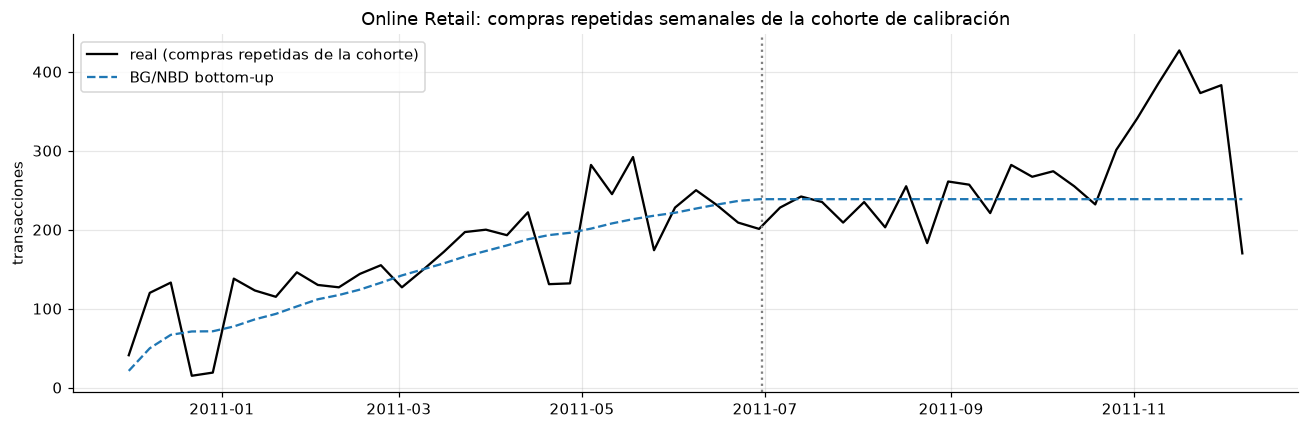

In [32]:
fig, ax = plt.subplots(figsize=(12, 4))
fechas5 = inicio5 + pd.to_timedelta((sem5 - 1) * 7, unit="D")
ax.plot(fechas5, real5, "k", label="real (compras repetidas de la cohorte)")
ax.plot(fechas5, bu5_sem, "C0--", label="BG/NBD bottom-up")
ax.axvline(data.RETAIL_FIN_CAL, color="gray", ls=":")
ax.set(title="Online Retail: compras repetidas semanales de la cohorte de calibración", ylabel="transacciones")
ax.legend()
guardar(fig, "5_2_online_retail")

**5.2 Respuesta.** El BG/NBD (que aquí es un NBD) pronostica 5,489
transacciones en el *holdout* contra 6,313 reales: **−13%**. Pero el error
no está repartido parejo. Mes a mes, el modelo pronostica una cantidad
casi constante (~1,050 por mes, porque nadie se muere y las tasas son
estacionarias): en julio y agosto **sobrepronostica** (+7% y +10%); desde
septiembre se queda corto, y en **noviembre se queda corto por 38%** (1,023
vs 1,643), y en los 8 días de diciembre por 41%.

Esto conecta directo con lo que aprendimos de noviembre en la tarea de
series de tiempo: la tienda tiene un **pico estacional fortísimo en
octubre–noviembre**, cuando los mayoristas hacen sus pedidos para la
temporada navideña. El BG/NBD supone que cada cliente compra según un
Poisson con tasa *constante* en el tiempo: no tiene ninguna pieza de
estacionalidad, así que no puede anticipar el pico. Además, la calibración
(diciembre a junio) casi no contiene temporada alta, así que el modelo
tampoco la "promedia" en su tasa. El subpronóstico no se debe a que el
modelo mate clientes (aquí ni siquiera hay muerte); es un problema de
**demanda estacional**, el mismo que en la tarea hacía fallar a los
métodos que no tenían componente estacional. Un BTYD para este negocio
necesitaría una tasa que varíe con el calendario, o calibrar con al menos
un año completo (por ejemplo con *Online Retail II*).

---
## Parte 6 (opcional): ¿le gana una regresión logística al BG/NBD?

### 6.1 La comparación ingenua

In [33]:
X6 = np.c_[x, tx, T]
logit = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))
filas, oof_ultimo = [], None
for seed in range(20):
    skf = StratifiedKFold(5, shuffle=True, random_state=seed)
    oof = np.zeros(len(Z))
    for tr, te in skf.split(X6, Z):
        m = logit().fit(X6[tr], Z[tr])
        oof[te] = m.predict_proba(X6[te])[:, 1]
        filas.append({"seed": seed, "AUC logit": roc_auc_score(Z[te], oof[te]),
                      "AUC BG/NBD": roc_auc_score(Z[te], pz[te]),
                      "Brier logit": brier_score_loss(Z[te], oof[te]),
                      "Brier BG/NBD": brier_score_loss(Z[te], pz[te])})
    oof_ultimo = oof
cv61 = pd.DataFrame(filas)
tabla(cv61.drop(columns="seed").agg(["mean", "std"]).T.round(4), "6_1_cv")

,mean,std
AUC logit,0.7790,0.0212
AUC BG/NBD,0.7569,0.0222
Brier logit,0.1561,0.0073
Brier BG/NBD,0.1612,0.0064


Coeficientes (variables estandarizadas):
x      0.465
t_x    0.795
T     -0.231
dtype: float64 
intercepto -1.035


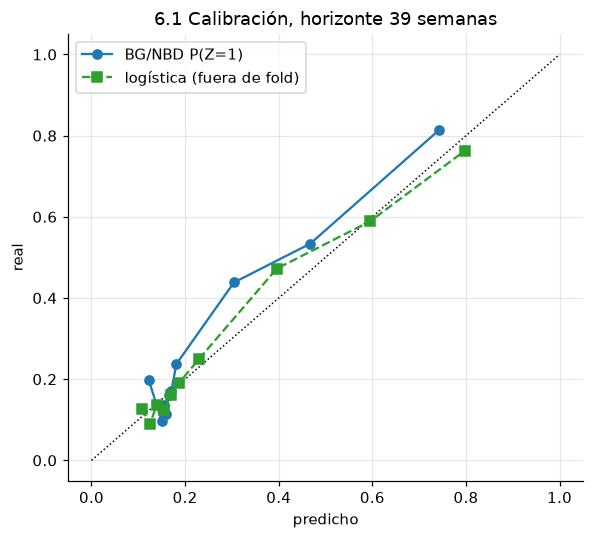

In [34]:
m61 = logit().fit(X6, Z)
coef = pd.Series(m61[-1].coef_[0], index=["x", "t_x", "T"])
print("Coeficientes (variables estandarizadas):")
print(coef.round(3), f"\nintercepto {m61[-1].intercept_[0]:.3f}")
cal61 = calib_deciles(oof_ultimo, Z)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.plot(cal45["predicho"], cal45["real"], "C0o-", label="BG/NBD P(Z=1)")
ax.plot(cal61["predicho"], cal61["real"], "C2s--", label="logística (fuera de fold)")
ax.set(xlabel="predicho", ylabel="real", title="6.1 Calibración, horizonte 39 semanas")
ax.legend()
guardar(fig, "6_1_calibracion")

**6.1 Respuesta.** Con validación cruzada estratificada de 5 *folds*
repetida con 20 semillas, la logística **gana**: AUC 0.779 ± 0.021 vs
0.757 ± 0.022 del BG/NBD, y Brier 0.156 vs 0.161. Su calibración fuera de
*fold* también es mejor (está casi sobre la diagonal, mientras que el
BG/NBD subestima los deciles altos).

Coeficientes (variables estandarizadas): **$t_x$ es la variable que más
pesa (+0.80)**, luego $x$ (+0.47), ambas positivas: más reciente y más
frecuente, más probable que compre. $T$ entra con signo **negativo**
(−0.23): a igual $x$ y $t_x$, un cliente más viejo lleva más tiempo en
silencio relativo, lo cual es mala señal. Es la misma lógica de "recencia
relativa a la edad" que el BG/NBD codifica con $(\alpha+T)/(\alpha+t_x)$.

**6.2 Respuesta. No fue justa.** La logística aprendió con las etiquetas
del *holdout* de los otros clientes: vio cómo se comportó *esta misma
cohorte* entre octubre de 1997 y junio de 1998, incluyendo el nivel de
compra de ese periodo, su estacionalidad y la duración exacta de 39
semanas. El BG/NBD nunca vio nada posterior al 30 de septiembre. El 30 de
septiembre de 1997 esas etiquetas **no existían**; las únicas etiquetas
disponibles eran de periodos pasados (por ejemplo, "¿compró entre julio y
septiembre?" usando características de antes de julio). Es la misma
**fuga de información** (*data leakage*) que en la tarea de series de
tiempo cuando se hace validación cruzada aleatoria sobre una serie: los
*folds* mezclan el futuro con el pasado y el modelo "ve" información que
en la vida real no tendría al momento de pronosticar.

### 6.3 La versión honesta

El 30 de septiembre sí podríamos haber entrenado la logística, pero con una
ventana del pasado: características $(x, t_x, T)$ calculadas con datos hasta
el 1 de julio de 1997 y etiqueta "compró entre el 2 de julio y el 30 de
septiembre" (13 semanas). Luego aplicamos ese modelo a $(x, t_x, T)$ del 30
de septiembre para predecir quién compra en las primeras 13 semanas del
*holdout*. Repetimos con 26 semanas (características al 1 de abril).

In [35]:
def honesta(corte, horizonte_sem):
    corte = pd.Timestamp(corte)
    fin_et = data.CDNOW_FIN_CAL
    fin_pred = data.CDNOW_FIN_CAL + pd.Timedelta(days=7 * horizonte_sem)
    tr = data.rfm(trans, corte, fin_et)
    te = data.rfm(trans, data.CDNOW_FIN_CAL, fin_pred)
    ytr = (tr["x_star"] >= 1).astype(int).to_numpy()
    yte = (te["x_star"] >= 1).astype(int).to_numpy()
    m = logit().fit(tr[["x", "tx", "T"]].to_numpy(), ytr)
    p_log = m.predict_proba(te[["x", "tx", "T"]].to_numpy())[:, 1]
    p_bg = bgnbd.p_buy(horizonte_sem, P, te["x"].to_numpy(), te["tx"].to_numpy(), te["T"].to_numpy())
    p_61 = m61.predict_proba(te[["x", "tx", "T"]].to_numpy())[:, 1]
    res = pd.DataFrame({
        "AUC": [roc_auc_score(yte, p_log), roc_auc_score(yte, p_bg), roc_auc_score(yte, p_61)],
        "Brier": [brier_score_loss(yte, p_log), brier_score_loss(yte, p_bg), brier_score_loss(yte, p_61)],
        "prob. media": [p_log.mean(), p_bg.mean(), p_61.mean()],
        "tasa real": yte.mean(),
    }, index=[f"logística honesta ({horizonte_sem} sem)", f"BG/NBD τ={horizonte_sem}",
              "logística 6.1 (entrenada a 39 sem)"])
    rangos = pd.DataFrame({"entrenamiento": [tr["T"].min(), tr["T"].max(), tr["x"].mean(), ytr.mean()],
                           "aplicación (30-sep)": [te["T"].min(), te["T"].max(), te["x"].mean(), yte.mean()]},
                          index=["T mín", "T máx", "x medio", "tasa de la etiqueta"])
    return res, rangos, (yte, p_log, p_bg, p_61), m


res13w, rangos13, curvas13, m13 = honesta("1997-07-01", 13)
res26w, rangos26, curvas26, m26 = honesta("1997-04-01", 26)
print("Horizonte 13 semanas"); print(res13w.round(4)); print(rangos13.round(2))
print("\nHorizonte 26 semanas"); print(res26w.round(4)); print(rangos26.round(2))
tabla(pd.concat([res13w, res26w]).round(4), "6_3_honesta")

Horizonte 13 semanas
                                       AUC   Brier  prob. media  tasa real
logística honesta (13 sem)          0.7921  0.1124       0.1377     0.1706
BG/NBD τ=13                         0.7845  0.1102       0.1537     0.1706
logística 6.1 (entrenada a 39 sem)  0.7909  0.1284       0.2902     0.1706
                     entrenamiento  aplicación (30-sep)
T mín                        14.00                27.00
T máx                        25.86                38.86
x medio                       0.74                 1.04
tasa de la etiqueta           0.17                 0.17

Horizonte 26 semanas
                                       AUC   Brier  prob. media  tasa real
logística honesta (26 sem)          0.7849  0.1559       0.2003     0.2512
BG/NBD τ=26                         0.7615  0.1475       0.2203     0.2512
logística 6.1 (entrenada a 39 sem)  0.7834  0.1454       0.2902     0.2512
                     entrenamiento  aplicación (30-sep)
T mín                

,AUC,Brier,prob. media,tasa real
logística honesta (13 sem),0.7921,0.1124,0.1377,0.1706
BG/NBD τ=13,0.7845,0.1102,0.1537,0.1706
logística 6.1 (entrenada a 39 sem),0.7909,0.1284,0.2902,0.1706
logística honesta (26 sem),0.7849,0.1559,0.2003,0.2512
BG/NBD τ=26,0.7615,0.1475,0.2203,0.2512
logística 6.1 (entrenada a 39 sem),0.7834,0.1454,0.2902,0.2512


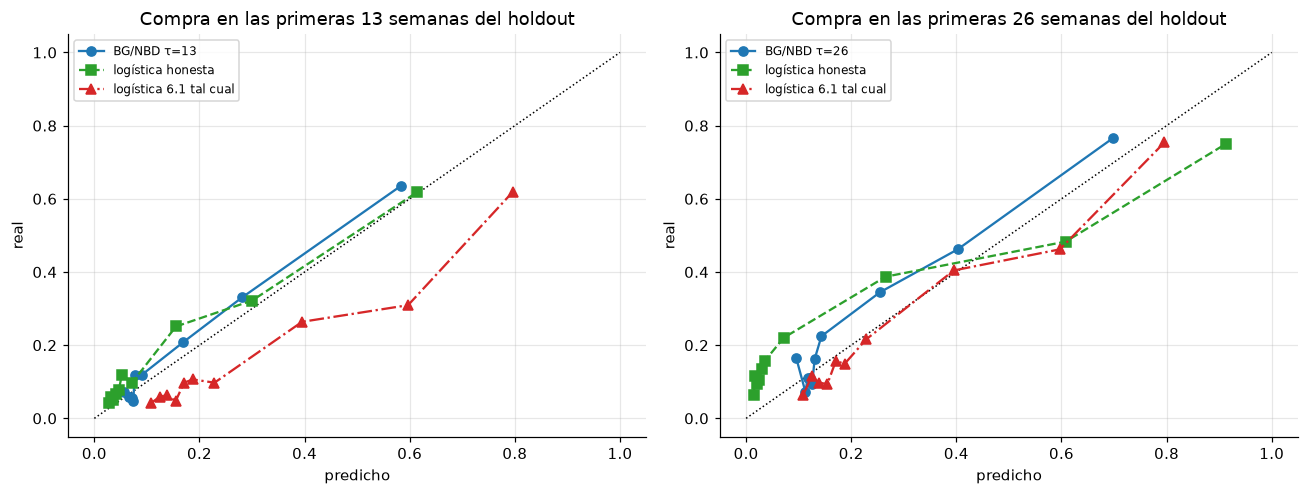

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for k, (curvas, hz) in enumerate([(curvas13, 13), (curvas26, 26)]):
    yte, p_log, p_bg, p_61 = curvas
    ax[k].plot([0, 1], [0, 1], "k:", lw=1)
    for p_, nom, est_ in [(p_bg, f"BG/NBD τ={hz}", "C0o-"), (p_log, "logística honesta", "C2s--"),
                          (p_61, "logística 6.1 tal cual", "C3^-.")]:
        c = calib_deciles(p_, yte)
        ax[k].plot(c["predicho"], c["real"], est_, label=nom)
    ax[k].set(title=f"Compra en las primeras {hz} semanas del holdout", xlabel="predicho", ylabel="real")
    ax[k].legend(fontsize=8)
guardar(fig, "6_3_6_4_calibracion")

**6.3 Respuesta.**

* **13 semanas.** La logística honesta ordena un poco mejor (AUC 0.792 vs
  0.785), pero el BG/NBD tiene **mejor Brier** (0.110 vs 0.112) y una
  probabilidad media más cercana a la real (15.4% vs 13.8%; real 17.1%).
  Prácticamente un empate, con ventaja del BG/NBD en niveles.
* **26 semanas.** De nuevo la logística ordena algo mejor (0.785 vs 0.762),
  pero sus probabilidades están peor calibradas: Brier 0.156 vs 0.148 del
  BG/NBD, probabilidad media 20.0% vs 22.0% (real 25.1%). En la gráfica se
  ve que la logística empuja demasiado a los extremos: a muchos clientes
  les da ~2% cuando compra el 10%, y al decil más alto 91% cuando compra el
  75%.
* **¿Qué le estamos pidiendo a la logística? Extrapolar.** Para el
  horizonte de 13 semanas se entrenó con $T$ entre 14 y 26 semanas y se
  aplica a clientes con $T$ entre 27 y 39: **ningún** cliente de aplicación
  está en el rango de entrenamiento. Para 26 semanas es peor: se entrenó con
  clientes de 1 a 13 semanas de edad (casi todos con $x=0$, cuando la
  cohorte apenas se formaba y su tasa de compra era 31%) y se aplica a
  clientes de 27 a 39 semanas, cuya tasa es 25%. La logística supone que la
  relación entre $(x,t_x,T)$ y la compra es la misma en otra etapa de la
  vida de la cohorte, y extiende linealmente (en el *logit*) el efecto de
  $T$ fuera de donde lo vio. El BG/NBD, en cambio, tiene una historia
  explícita de cómo cambian las cosas con la edad del cliente (muerte
  acumulada, posterior de $\lambda$ que se actualiza con $T$), y por eso
  extrapola en el tiempo de forma natural.

### 6.4 Cambiar la pregunta

**6.4 Respuesta.** Con el BG/NBD basta cambiar $\tau=39$ por $\tau=13$ en
la fórmula de 4.3. Con la logística de 6.1 habría que **reentrenar con
etiquetas de 13 semanas** — que, igual que en 6.2, no existen el 30 de
septiembre sin recurrir a una ventana pasada como en 6.3. Usándola tal
cual: el orden casi no cambia (AUC 0.791, el orden de 39 semanas sirve
para 13), pero las **probabilidades quedan infladas**: promedian 29.0% (la
tasa de 39 semanas con la que se entrenó) cuando la tasa real a 13 semanas
es 17.1%. En la gráfica de calibración (triángulos rojos, panel izquierdo)
toda la curva queda muy por debajo de la diagonal: el decil más alto
predice 80% y compra el 62%. Su Brier (0.128) es claramente peor que el del
BG/NBD (0.110). La logística respondió una pregunta (39 semanas) y no sabe
responder otra; el horizonte está "horneado" en sus etiquetas.

### 6.5 Veredicto

Usaríamos una **regresión logística** cuando la pregunta sea fija y
repetida (siempre el mismo horizonte), cuando importe sobre todo **ordenar**
clientes (a quién llamar primero), cuando existan **etiquetas de un periodo
anterior comparable** (misma etapa de vida de la base, misma temporada) y
cuando queramos meter otras variables (monto, canal, demografía) que el
BTYD no usa; con esas condiciones ordena igual o un poco mejor. Usaríamos el
**BG/NBD** cuando necesitemos **niveles** y no solo un orden (cuántos
clientes van a comprar, cuántas compras habrá, el CLV), cuando el horizonte
cambie (13, 26, 39 semanas con el mismo ajuste), cuando haya que
pronosticar el **total de la base** de abajo hacia arriba como en la Parte 3,
y sobre todo cuando **no haya etiquetas de un periodo anterior** (una
cohorte nueva, o al inicio de la relación): el BG/NBD se calibra solo con la
historia de compras y no necesita que nadie le diga qué pasó después. La
comparación de 6.1 favorecía a la logística solo porque le dejamos ver el
futuro; en la versión honesta (6.3) ordenan parecido y el BG/NBD da mejores
probabilidades. Y si hay buenas etiquetas, lo mejor de ambos mundos es
usar $P(Z=1)$ y $E[Y(\tau)]$ del BG/NBD como variables dentro de la
logística.

---
## Conclusiones

1. **El modelo está bien programado:** la verosimilitud a mano recupera
   los parámetros de datos simulados (Parte 1) y reproduce al decimal los
   estimados del artículo en CDNOW, su subpronóstico acumulado de 4% y sus
   esperanzas condicionales (Partes 2–3).
2. **Bottom-up vs top-down:** con solo $(x,t_x,T)$ y la fecha de primera
   compra, el BG/NBD pronostica el *holdout* mejor que casi todos los
   métodos de series de tiempo, sin escoger ventanas, porque sabe que la
   cohorte está cerrada y que los clientes se van muriendo.
3. **"Vivo" no es "va a comprar":** el supuesto de que solo se muere tras
   una recompra hace que $P(\text{vivo})=1$ para los clientes de una sola
   compra y que, como clasificador, sea peor que el azar. La probabilidad
   correcta, $P(Z=1)$, ordena tan bien como la recencia y además está en
   unidades de probabilidad. El MBG/NBD cambia una sola pieza y arregla
   $P(\text{vivo})$ sin cambiar casi nada de $P(Z=1)$.
4. **El BG/NBD es una elección, no "el" modelo:** en Online Retail
   (mayoristas, calibración corta, sin cohorte real) el componente de muerte
   desaparece y el modelo colapsa al NBD; y como no tiene estacionalidad, no
   ve venir noviembre.
5. **Logística vs BG/NBD:** la logística solo "gana" cuando se le deja ver
   el futuro; en una comparación honesta ordenan parecido, y el BG/NBD
   calibra mejor, cambia de horizonte gratis y no necesita etiquetas.

### Referencias

* Fader, Hardie y Lee (2005). "Counting Your Customers" the Easy Way: An
  Alternative to the Pareto/NBD Model. *Marketing Science* 24(2):275–284.
* Schmittlein, Morrison y Colombo (1987). Counting Your Customers.
  *Management Science* 33(1):1–24.
* Batislam, Denizel y Filiztekin (2007). Empirical validation and
  comparison of models for customer base analysis. *IJRM* 24(3):201–209.
* Fader y Hardie (2009). Probability Models for Customer-Base Analysis.
  *Journal of Interactive Marketing* 23(1):61–69.
* Hyndman y Athanasopoulos (2018). *Forecasting: Principles and Practice*,
  2a ed., §10.3–10.4.
* Datos: B. Hardie, CDNOW_sample (brucehardie.com/datasets); D. Chen,
  Online Retail, UCI ML Repository.